# Retrieval series: the retrievals against the noiseless predictions

Every stored retrieval against the prediction of the noiseless analysis (`retrieval.prediction.run_prediction`; theory in `bias_analysis/04_evidence_prediction.ipynb`). The simulated noise $z = (y_{\rm obs} - y_{\rm true})/\sigma$ is known, so each run has its own prediction without sampling: $\ln B \approx \chi^2_{\min}/2 + \zeta\sqrt{\chi^2_{\min}}$ with $\zeta = \hat r_\perp\cdot z$, the noiseless bias and Fisher $\sigma_{A_B}$ for the $A_B$ posterior, and $\max(z_F^{\rm noiseless} + \zeta_F, 0)$ for the significance $z_F$ of the spurious $F$. The runs are grouped in `SERIES`; runs whose difference is not in the file name sit in `null_test/` and `free_geometry/`.

In [1]:
import numpy as np
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display
from scipy.stats import kstest, norm
from hyperphase.bias.fits import fit_naive
from hyperphase.model import model_pcurve
from hyperphase.plotting.retrieval import plot_ns_check, plot_ns_distribution, plot_ns_realizations
from hyperphase.retrieval.prediction import evidence_reference, run_prediction, series_summary, series_table
from hyperphase.retrieval.sampler import posterior_summary
from hyperphase.retrieval.storage import find_dataset, list_datasets, load_fits
from hyperphase.bias.evidence import evidence_probability   # the noiseless fits of the bias analysis, for the special runs of section 6; P(ln B > x) of the linear prediction, for section 7
from hyperphase.bias.fisher import fit_truth
from hyperphase.bands import detector_label, JWST_BANDS
from hyperphase.defaults import A_B_BOUNDS, A_B_FIT_BOUNDS, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_ORBITS
from hyperphase.noise import observable   # False for the modes a planet cannot be observed in (UNOBSERVABLE: 55 Cnc e saturates NIRSpec/G395H, so MIRI/LRS only)
from hyperphase.paper import PAPER_PLANETS
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor", module="joblib")   # loky replaces a worker whose memory grew (SPIDERMAN's allocator) and warns; its jobs are rerun, the results are unaffected

RESULTS_DIR = "dynesty_results"   # where run_dynesty.py saves; subfolders null_test/ and free_geometry/
N_JOBS = -1                       # the noiseless references and the rows run process-parallel (loky)
K_JITTER = 200                    # jittered realisations for the sampler error of ln B (0: analytic errors only)

In [2]:
# The series, as the keywords of find_dataset (planet, instrument, the settings that deviate from the baseline: seed 42, pfrac 0.8, A_B, n_bins, n_orbits of hyperphase.defaults).
JOINT, LRS = "JWST_NIRSpec.G395H_joint", "MIRI/LRS"
NRS1, NRS2 = JWST_BANDS[:2]
IMAGING = ("MIRI/F1280W", "MIRI/F1500W", "MIRI/F1800W")
THREE = (NRS1, NRS2, LRS)                      # one joint fit of the three detectors
T, K = "TOI-2431 b", "K2-141 b"

PAPER_SEEDS = {p: range(40, 70) if p in (T, K) else range(40, 44) for p in PAPER_PLANETS}   # noise realisations of the paper's retrievals: thirty for the reference planets, four for the others
FREE_SEEDS = range(61, 65)   # the free-geometry runs of the reference planets; each has a fixed-geometry twin of the same seed among the paper's retrievals (section 6)
PAPER_SERIES = {f"{p}, {lab}": [dict(planet=p, instrument=ins, seed=s) for s in PAPER_SEEDS[p]] for p in PAPER_PLANETS for ins, lab in ((JOINT, "joint NIRSpec"), (LRS, "MIRI/LRS")) if observable(p, ins)}

SERIES = {
    # --- the paper's retrievals: every paper planet in the two primary modes at the baseline settings, pfrac 0.8 (section 7) -----------
    **PAPER_SERIES,
    # --- seed 42: the single bands of the reference planets -------------------------------------------------------------------------
    "seed 42, single bands":        [dict(planet=T, instrument=ins) for ins in (NRS1, NRS2, *IMAGING)] + [dict(planet=K, instrument=ins) for ins in (NRS1, NRS2)],
    # --- TOI-2431 b, one setting changed at a time --------------------------------------------------------------------------------
    "TOI-2431 b, n_orbits 3 / 10":  [dict(planet=T, instrument=ins, n_orbits=n, **kw) for ins in (JOINT, LRS) for n, kw in ((3, {}), (10, {}), (10, dict(seed=43)))],
    "TOI-2431 b, n_bins 20 / 36":   [dict(planet=T, instrument=ins, n_bins=n) for ins in (JOINT, LRS) for n in (20, 36)],
    "TOI-2431 b, A_B = 0.4":        [dict(planet=T, instrument=ins, A_B=0.4) for ins in (JOINT, LRS)],
    # --- special runs --------------------------------------------------------------------------------------------------------------
    "three detectors":              [dict(planet=p, instrument=THREE, seed=43) for p in (T, K)],
    "free geometry":                [dict(planet=p, instrument=ins, seed=s, subfolder="free_geometry") for p in (T, K) for ins in (JOINT, LRS) for s in FREE_SEEDS],
    "null test":                    [dict(planet=T, instrument=ins, seed=s, subfolder="null_test") for ins in (JOINT, LRS) for s in (43, 44, 45)],
    "TOI-2431 b, A_B = 0.05":       [dict(planet=T, instrument=ins, A_B=0.05, seed=43) for ins in (JOINT, LRS)],
    "TOI-2431 b LRS, 2 orbits":     [dict(planet=T, instrument=LRS, n_orbits=2, seed=s) for s in range(43, 48)],
    # --- the same data at another pfrac: NOT part of the paper's series, only of the per-run checks and the pfrac comparison ------------
    "TOI-2431 b joint (pfrac 0)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=0) for s in range(40, 50)],
    "TOI-2431 b joint (pfrac 1)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=1) for s in range(43, 47)],
    "TOI-2431 b LRS (other pfrac)": [dict(planet=T, instrument=LRS, seed=s, pfrac=p) for s, p in ((43, 0), (44, 0), (45, 1), (46, 1))],
}

# every stored run should be in a series: the stems on disk that no entry names
ALL = {f"{name} | {k}": kw for name, entries in SERIES.items() for k, kw in enumerate(entries)}
have = list_datasets(RESULTS_DIR)
on_disk = {os.path.join(sub, tag) if sub else tag for sub, tag in zip(have.subfolder, have.tag)}
listed = set()
for kw in ALL.values():
    try: listed.add(find_dataset(RESULTS_DIR, **kw))
    except FileNotFoundError: pass
print(f"{len(on_disk)} datasets in {RESULTS_DIR}/ (with subfolders), {len(listed)} of them in a series")
for stem in sorted(on_disk - listed): print(f"   run not in any series: {stem}")

250 datasets in dynesty_results/ (with subfolders), 248 of them in a series
   run not in any series: free_geometry/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed44_pfrac0.8
   run not in any series: test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed42_pfrac0


## 1. The table: one row per run

`series_table` regenerates each configuration's noiseless truth once, fits the misspecified models to it at the truth's resolution (with `redist=True` also the fit with redistribution) and evaluates every run against it. Each row asserts that $z$ reproduces `default_rng(seed)` (`z_dev`: the largest deviation). Missing and incomplete runs are listed.

In [3]:
tab, missing = series_table(RESULTS_DIR, SERIES, K=K_JITTER, n_jobs=N_JOBS, redist=True)
tab["mode"] = tab["instrument"].map(lambda ins: {JOINT: "joint NIRSpec", "joint-NRS1+NRS2+LRS": "NIRSpec + LRS", LRS: "MIRI/LRS"}.get(ins, detector_label(ins)))   # short labels: NRS1, NRS2, F1280W, ...
runs = tab.drop_duplicates("stem")   # a run named by two series would count twice: every statistic over ALL runs uses each once

print(f"{len(runs)} runs evaluated ({len(tab)} series rows), {len(missing)} missing or incomplete:")
miss = pd.DataFrame([dict(series=name, **{k: (v if isinstance(v, (str, int, float)) else "+".join(x.split("_")[-1].split("/")[-1] for x in v)) for k, v in kw.items()}, reason=why) for name, kw, why in missing])
if len(miss): print(miss.fillna("").to_string(index=False))
stale = runs[runs["grid_change"] > 1e-6]
if len(stale): print(f"\nSTALE pickles (stellar grid changed since the run): {', '.join(stale['stem'])}")

248 runs evaluated (248 series rows), 0 missing or incomplete:


## 2. Validation: $\zeta$ from the noise against $\zeta$ from the sampler

$\zeta = \hat r_\perp\cdot z$ from the simulated noise against $\zeta_{\rm inferred} = (2\,\Delta\ln\mathcal{L}_{\max} - \chi^2_{\min})/(2\sqrt{\chi^2_{\min}})$ from the sampler's best likelihoods: the `N_SHOW` runs with the largest deviation (`chk` holds all), then a summary over all runs, the last line for $z_F$. They differ where the sampler resolves $\ln\mathcal{L}_{\max}$ poorly or the prior edge $A_B \geq 0$ cuts the posterior. `ΔH` is the difference in information between the models; `χ²_min / floor` must be large.

In [4]:
# Table helpers for sections 2 and 3: `setting` names what a run changes from the baseline of hyperphase.defaults (kind of run, A_B, n_bins, n_orbits) in one column instead of four
setting = lambda r: ", ".join(s for s, on in ((str(r["kind"]).replace("_", " "), r["kind"] != ""), (f"A_B = {r['A_B_true']:g}", r["A_B_true"] != DEFAULT_A_B),
                                                (f"{r['n_bins']:g} bins", r["n_bins"] != DEFAULT_N_BINS), (f"{r['n_orbits']:g} orbits", r["n_orbits"] != DEFAULT_N_ORBITS)) if on) or "baseline"
fmt = lambda f: (lambda v: "-" if pd.isna(v) else f.format(v))
pm = lambda m, s, f: "-" if pd.isna(m) else f.format(m) + ("" if pd.isna(s) else " ± " + f.format(s))   # value ± error (or ± sd), the ± only where defined

chk = runs.assign(dzeta=runs["zeta"] - runs["zeta_inferred"], dlnB=runs["lnB"] - runs["lnB_pred"])
chk = chk.reindex(chk["dzeta"].abs().sort_values(ascending=False).index)   # largest deviation first
N_SHOW, ZETA_TOL = 10, 0.1   # runs listed in the tables of sections 2 and 3 (largest deviations; chk and tab hold every run); tolerance on zeta, whose scatter is 1
top = chk.head(N_SHOW)
print(f"|ζ − ζ_inferred| > {ZETA_TOL:g} in {(chk['dzeta'].abs() > ZETA_TOL).sum()} of {len(chk)} runs; the {N_SHOW} largest:")
display(pd.DataFrame({"planet": top["planet"], "mode": top["mode"], "setting": top.apply(setting, axis=1), "seed": top["seed"], "pfrac": top["pfrac"].map(fmt("{:g}")),
                      "χ²_min": top["chi2_min"].map(fmt("{:.2f}")), "χ²_min / floor": (top["chi2_min"] / top["chi2_floor"]).map(fmt("{:.0f}")),
                      "ζ": top["zeta"].map(fmt("{:+.2f}")), "ζ − ζ_inferred": top["dzeta"].map(fmt("{:+.3f}")), "prediction": top["lnB_pred"].map(fmt("{:.2f}")),
                      "ln B": [pm(v, e, "{:.2f}") for v, e in zip(top["lnB"], top["lnB_err_jitter"])], "ln B − prediction": top["dlnB"].map(fmt("{:+.2f}")),
                      "ΔH": top["dH"].map(fmt("{:+.2f}"))}).style.hide(axis="index"))
base = chk[(chk["kind"] == "") & (chk["A_B_true"] >= 0.2)]
print(f"\nbaseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = {base['dzeta'].abs().max():.3f}, rms {np.sqrt(np.mean(base['dzeta'] ** 2)):.3f};  "
      f"max |ln B - prediction| = {base['dlnB'].abs().max():.2f}, rms {np.sqrt(np.mean(base['dlnB'] ** 2)):.2f};  max |dH| = {base['dH'].abs().max():.2f};  max z_dev = {runs['z_dev'].max():.1e}")
print(f"chi2_min / chi2_floor >= {np.nanmin(runs['chi2_min'] / runs['chi2_floor']):.0f} in every run")
dzF = (base["zF_obs"] - base["zF_pred"]).dropna()
print(f"fit with redistribution, the same runs ({len(dzF)}): z_F - max(z_F,noiseless + zeta_F, 0): max |.| = {dzF.abs().max():.2f}, rms {np.sqrt(np.mean(dzF ** 2)):.2f};  corr = {np.corrcoef(base.loc[dzF.index, 'zF_obs'], base.loc[dzF.index, 'zF_pred'])[0, 1]:.3f}")

|ζ − ζ_inferred| > 0.1 in 13 of 248 runs; the 10 largest:


planet,mode,setting,seed,pfrac,χ²_min,χ²_min / floor,ζ,ζ − ζ_inferred,prediction,ln B,ln B − prediction,ΔH
TOI-2431 b,MIRI/LRS,A_B = 0.05,43,0.8,15.03,15430,-0.29,-0.283,6.37,8.04 ± 0.13,+1.67,-0.34
K2-141 b,MIRI/LRS,baseline,49,0.8,4.13,7841,-1.81,-0.251,-1.61,-1.12 ± 0.11,+0.49,+0.03
K2-141 b,MIRI/LRS,free geometry,63,0.8,3.94,7407,+1.77,-0.240,5.49,6.20 ± 0.15,+0.71,-0.01
K2-141 b,MIRI/LRS,baseline,56,0.8,4.13,7841,+2.71,+0.226,7.57,7.06 ± 0.11,-0.52,+0.06
TOI-2431 b,MIRI/LRS,free geometry,61,0.8,12.22,15376,-1.88,-0.206,-0.45,-0.49 ± 0.15,-0.03,+0.24
TOI-2431 b,joint NIRSpec,free geometry,63,0.8,11.20,7162,+1.32,+0.181,10.01,10.19 ± 0.24,+0.17,-0.11
TOI-2431 b,MIRI/LRS,baseline,49,0.8,12.69,14933,-1.82,-0.159,-0.13,0.44 ± 0.12,+0.57,+0.01
TOI-2431 b,joint NIRSpec,free geometry,64,0.8,11.20,7162,+1.40,+0.158,10.27,10.63 ± 0.21,+0.36,-0.24
K2-141 b,MIRI/LRS,baseline,63,0.8,4.13,7841,+1.25,-0.156,4.60,5.42 ± 0.12,+0.82,-0.27
TOI-2431 b,MIRI/LRS,free geometry,64,0.8,12.22,15376,+1.43,+0.150,11.09,11.17 ± 0.15,+0.08,-0.14



baseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = 0.251, rms 0.040;  max |ln B - prediction| = 0.82, rms 0.18;  max |dH| = 0.40;  max z_dev = 1.5e-14
chi2_min / chi2_floor >= 478 in every run
fit with redistribution, the same runs (224): z_F - max(z_F,noiseless + zeta_F, 0): max |.| = 0.86, rms 0.12;  corr = 0.995


## 3. Series: measured against predicted

Mean ± sd over the runs of each series (`series_summary`): the measured $\ln B$ against its per-run prediction and against $\chi^2_{\min}/2$, the paired median difference of $A_B$ against the noiseless bias, and the posterior width against the Fisher $\sigma$, which drops below 1 where the prior cuts the posterior. Then the `N_SHOW` runs whose median difference lies farthest from the noiseless bias.

In [5]:
# Series summary, split into ln B and A_B: mean ± sd over the runs of each series (no sd for a single run). The helpers are those of section 2.
summary = series_summary(tab)
both = lambda name, f="{:.2f}": [pm(m, s, f) for m, s in zip(summary[name], summary[name + " sd"])]
print("ln B, extended vs point source")
display(pd.DataFrame({"n": summary["n"], "seeds": summary["seeds"], "pfrac": summary["pfrac"], "ln B": both("lnB"), "prediction": both("lnB_pred"),
                      "χ²_min / 2": both("lnB_expected"), "ln B − prediction": both("lnB - pred"), "ζ": both("zeta"), "ζ − ζ_inferred": both("zeta - zeta_inferred", "{:.3f}")}))
print("A_B: paired posterior-median difference against the noiseless bias, posterior width against the Fisher sigma")
display(pd.DataFrame({"n": summary["n"], "ΔA_B, posterior medians": both("dA_median", "{:.4f}"), "ΔA_B, noiseless": both("dA_noiseless", "{:.4f}"),
                      "σ_post / σ_Fisher": both("sigma_post/sigma_F")}))

A_TOL = 0.5   # tolerance on the paired median difference against the noiseless bias, in posterior widths
dev = (tab["dA_median"] - tab["dA_noiseless"]) / tab["sigma_post"]
top = tab.reindex(dev.abs().sort_values(ascending=False).index).head(N_SHOW)
print(f"individual runs: |ΔA_B, medians − ΔA_B, noiseless| > {A_TOL:g} σ_post in {(dev.abs() > A_TOL).sum()} of {len(tab)}; the {N_SHOW} largest:")
display(pd.DataFrame({"series": top["series"], "planet": top["planet"], "mode": top["mode"], "setting": top.apply(setting, axis=1), "seed": top["seed"], "pfrac": top["pfrac"].map(fmt("{:g}")),
                      "ΔA_B, noiseless": top["dA_noiseless"].map(fmt("{:+.4f}")), "ΔA_B, medians": top["dA_median"].map(fmt("{:+.4f}")), "σ_Fisher": top["sigma_fisher"].map(fmt("{:.4f}")),
                      "σ_post": top["sigma_post"].map(fmt("{:.4f}")), "difference / σ_post": dev[top.index].map(fmt("{:+.2f}")), "converged": top["converged"]}).style.hide(axis="index"))
nc = tab[~tab["converged"].astype(bool)]
if len(nc): print(f"not converged ({len(nc)} of {len(tab)}): " + ", ".join(f"{r.planet} {r.mode} seed {r.seed}" for r in nc.itertuples()))


ln B, extended vs point source


,n,seeds,pfrac,ln B,prediction,χ²_min / 2,ln B − prediction,ζ,ζ − ζ_inferred
series,,,,,,,,,
"TOI-2431 b, joint NIRSpec",30,"40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,5...",0.8,5.41 ± 3.30,5.44 ± 3.24,5.82 ± 0.00,-0.03 ± 0.16,-0.11 ± 0.95,-0.003 ± 0.024
"TOI-2431 b, MIRI/LRS",30,"40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,5...",0.8,6.41 ± 3.90,6.43 ± 3.93,6.35 ± 0.00,-0.01 ± 0.21,0.02 ± 1.10,-0.006 ± 0.044
"TOI-2260 b, joint NIRSpec",4,"40,41,42,43",0.8,1.58 ± 0.76,1.61 ± 0.71,1.81 ± 0.00,-0.03 ± 0.08,-0.11 ± 0.37,-0.011 ± 0.012
"TOI-2260 b, MIRI/LRS",4,"40,41,42,43",0.8,0.74 ± 1.48,0.65 ± 1.34,0.99 ± 0.00,0.08 ± 0.18,-0.24 ± 0.95,-0.014 ± 0.028
"K2-141 b, joint NIRSpec",30,"40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,5...",0.8,2.30 ± 2.15,2.37 ± 2.13,2.59 ± 0.00,-0.07 ± 0.15,-0.10 ± 0.93,-0.004 ± 0.033
"K2-141 b, MIRI/LRS",30,"40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,5...",0.8,2.20 ± 2.20,2.11 ± 2.19,2.07 ± 0.00,0.10 ± 0.27,0.02 ± 1.08,-0.012 ± 0.072
"K2-131 b, joint NIRSpec",4,"40,41,42,43",0.8,0.30 ± 0.23,0.32 ± 0.20,0.46 ± 0.00,-0.01 ± 0.08,-0.15 ± 0.21,-0.003 ± 0.017
"K2-131 b, MIRI/LRS",4,"40,41,42,43",0.8,0.15 ± 0.67,0.01 ± 0.60,0.19 ± 0.00,0.14 ± 0.11,-0.29 ± 0.98,-0.050 ± 0.038
"TOI-561 b, joint NIRSpec",4,"40,41,42,43",0.8,0.47 ± 0.37,0.61 ± 0.27,0.81 ± 0.00,-0.15 ± 0.16,-0.16 ± 0.21,-0.003 ± 0.018


A_B: paired posterior-median difference against the noiseless bias, posterior width against the Fisher sigma


,n,"ΔA_B, posterior medians","ΔA_B, noiseless",σ_post / σ_Fisher
series,,,,
"TOI-2431 b, joint NIRSpec",30,-0.0431 ± 0.0025,-0.0418 ± 0.0000,1.00 ± 0.02
"TOI-2431 b, MIRI/LRS",30,-0.0580 ± 0.0072,-0.0588 ± 0.0000,0.95 ± 0.06
"TOI-2260 b, joint NIRSpec",4,-0.0288 ± 0.0010,-0.0272 ± 0.0000,1.00 ± 0.02
"TOI-2260 b, MIRI/LRS",4,-0.0208 ± 0.0109,-0.0274 ± 0.0000,0.74 ± 0.09
"K2-141 b, joint NIRSpec",30,-0.0432 ± 0.0033,-0.0416 ± 0.0000,1.00 ± 0.02
"K2-141 b, MIRI/LRS",30,-0.0511 ± 0.0129,-0.0626 ± 0.0000,0.83 ± 0.11
"K2-131 b, joint NIRSpec",4,-0.0284 ± 0.0021,-0.0271 ± 0.0000,0.98 ± 0.02
"K2-131 b, MIRI/LRS",4,-0.0215 ± 0.0122,-0.0409 ± 0.0000,0.61 ± 0.10
"TOI-561 b, joint NIRSpec",4,-0.0292 ± 0.0010,-0.0278 ± 0.0000,1.01 ± 0.02


individual runs: |ΔA_B, medians − ΔA_B, noiseless| > 0.5 σ_post in 7 of 248; the 10 largest:


series,planet,mode,setting,seed,pfrac,"ΔA_B, noiseless","ΔA_B, medians",σ_Fisher,σ_post,difference / σ_post,converged
"TOI-2431 b, A_B = 0.05",TOI-2431 b,MIRI/LRS,A_B = 0.05,43,0.8,-0.0707,-0.0153,0.0600,0.0201,+2.76,True
"TOI-2431 b, A_B = 0.05",TOI-2431 b,joint NIRSpec,A_B = 0.05,43,0.8,-0.0511,-0.0232,0.0297,0.0138,+2.01,True
"K2-141 b, MIRI/LRS",K2-141 b,MIRI/LRS,baseline,63,0.8,-0.0626,-0.0192,0.0853,0.0449,+0.97,True
free geometry,K2-141 b,MIRI/LRS,free geometry,63,0.8,-0.0422,-0.0041,0.1182,0.0497,+0.77,True
free geometry,TOI-2431 b,MIRI/LRS,free geometry,63,0.8,-0.0476,-0.0160,0.0773,0.0433,+0.73,True
"K2-141 b, MIRI/LRS",K2-141 b,MIRI/LRS,baseline,48,0.8,-0.0626,-0.0288,0.0853,0.0484,+0.70,True
"K2-141 b, MIRI/LRS",K2-141 b,MIRI/LRS,baseline,55,0.8,-0.0626,-0.0316,0.0853,0.0484,+0.64,True
"TOI-2431 b, MIRI/LRS",TOI-2431 b,MIRI/LRS,baseline,63,0.8,-0.0588,-0.0415,0.0530,0.0406,+0.43,True
"K2-141 b, MIRI/LRS",K2-141 b,MIRI/LRS,baseline,56,0.8,-0.0626,-0.0316,0.0853,0.0749,+0.41,True
"K2-141 b, MIRI/LRS",K2-141 b,MIRI/LRS,baseline,45,0.8,-0.0626,-0.0369,0.0853,0.0620,+0.41,True


not converged (3 of 248): TOI-2431 b MIRI/LRS seed 43, TOI-2431 b MIRI/LRS seed 45, TOI-2431 b MIRI/LRS seed 46


**Figure `ns_check`.** (a) Paired median difference against the noiseless bias, (b) posterior width against the Fisher $\sigma$, (c) measured against predicted $\ln B$ with the sampler's error bars, (d) significance of $F$ against its prediction; dashed: one-to-one. (a) and (b) leave the line where the posterior is cut at $A_B = 0$; (c) and (d) should follow it over their whole range.

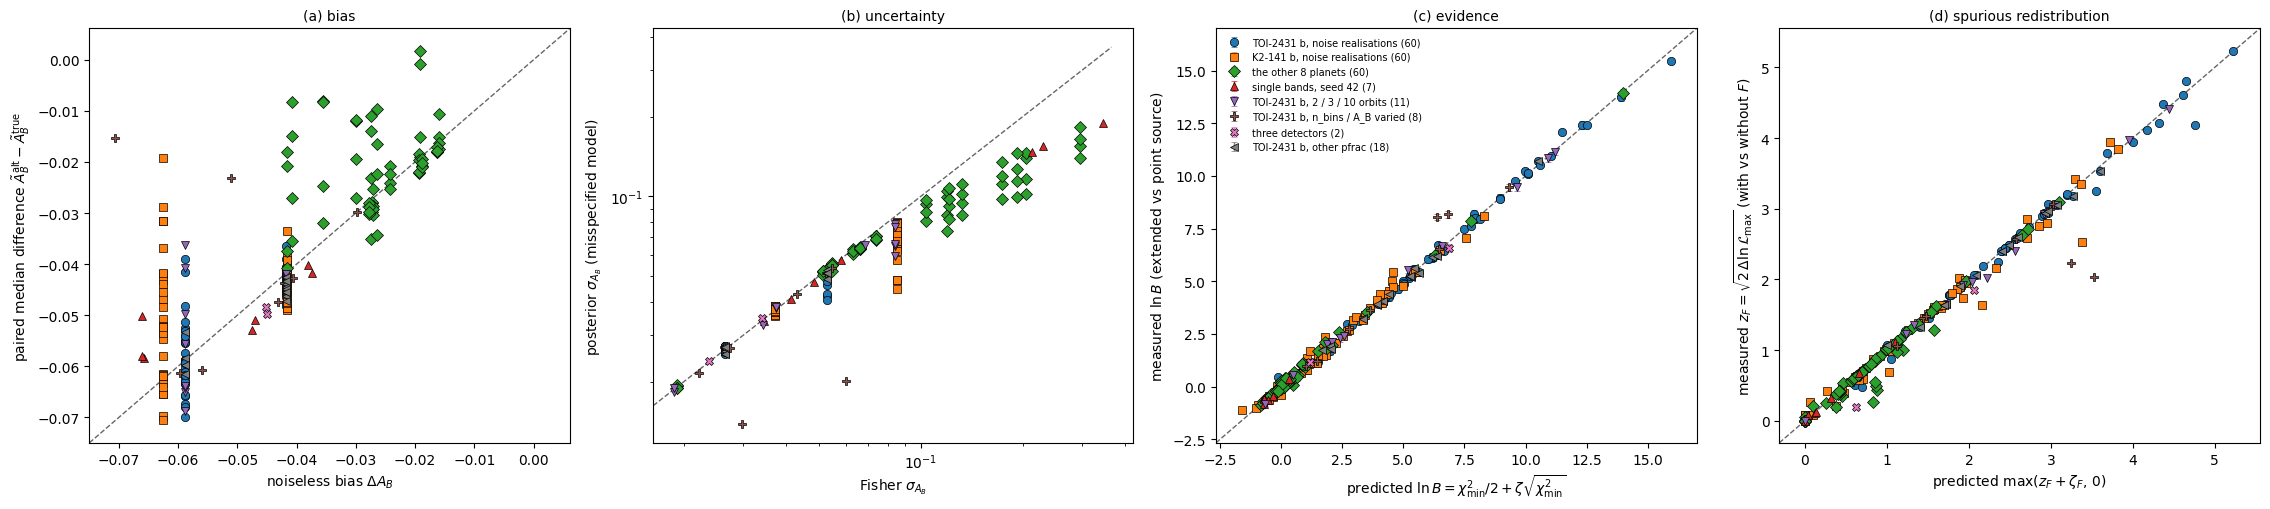

226 of 248 runs shown (null-test and free-geometry runs are compared with their own predictions in section 6)


In [6]:
is_ = lambda name: (runs["series"] == name).to_numpy()
normal = (runs["kind"] == "").to_numpy()
ref_T = normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & (runs["n_bins"] == 27).to_numpy() & (runs["A_B_true"] == 0.2).to_numpy() & runs["mode"].isin(["joint NIRSpec", "MIRI/LRS"]).to_numpy()
paper = runs["series"].isin(PAPER_SERIES).to_numpy()
GROUPS = {"TOI-2431 b, noise realisations": paper & (runs["planet"] == T).to_numpy(),
          "K2-141 b, noise realisations": paper & (runs["planet"] == K).to_numpy(),
          f"the other {len(PAPER_PLANETS) - 2} planets": paper & ~runs["planet"].isin([T, K]).to_numpy(),
          "single bands, seed 42": is_("seed 42, single bands"),
          "TOI-2431 b, 2 / 3 / 10 orbits": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] != 5).to_numpy(),
          "TOI-2431 b, n_bins / A_B varied": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & ((runs["n_bins"] != 27) | (runs["A_B_true"] != 0.2)).to_numpy(),
          "three detectors": normal & (runs["mode"] == "NIRSpec + LRS").to_numpy(),
          "TOI-2431 b, other pfrac": ref_T & (runs["pfrac"] != 0.8).to_numpy()}
shown = np.any(list(GROUPS.values()), axis=0)
fig, axes = plot_ns_check(runs, groups=GROUPS)
plt.show()
print(f"{int(shown.sum())} of {len(runs)} runs shown (null-test and free-geometry runs are compared with their own predictions in section 6)")

## 4. Same seed, other number of orbits

One seed gives the same $z$ for any number of orbits, and $\sigma_{\rm bin} \propto 1/\sqrt{n_{\rm orbits}}$, so runs of the same planet, mode and seed share $\zeta$ and
$$2\,\Delta\ln\mathcal{L}_{\max}(n) = \tfrac{n}{5}\chi^2_{\min} + 2\zeta\sqrt{\tfrac{n}{5}\chi^2_{\min}} .$$
The cell pairs every run at another number of orbits with the 5-orbit run of the same seed and compares this scaled prediction with the measured $2\,\Delta\ln\mathcal{L}_{\max}$ and $\ln B$.

In [7]:
key = ["planet", "mode", "seed"]
five = runs[(runs["kind"] == "") & (runs["n_orbits"] == 5) & (runs["n_bins"] == 27) & (runs["A_B_true"] == 0.2)].sort_values("pfrac").drop_duplicates(key, keep="last").set_index(key)   # the pfrac 0.8 / 1 run where a seed has several
rows = []
for _, r in runs[(runs["kind"] == "") & (runs["n_orbits"] != 5)].iterrows():
    k = (r["planet"], r["mode"], r["seed"])
    if k not in five.index: rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], note="no 5-orbit run of this seed")); continue
    b = five.loc[k]
    c = r["n_orbits"] / 5. * b["chi2_min"]
    rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], zeta_5=b["zeta"], zeta_n=r["zeta"], dchi2_scaled=c + 2. * b["zeta"] * np.sqrt(c), dchi2_measured=2. * r["dlnL_max"],
                     lnB_scaled=0.5 * c + b["zeta"] * np.sqrt(c), lnB_measured=r["lnB"], lnB_err=r["lnB_err_jitter"]))
print(pd.DataFrame(rows).sort_values(["planet", "mode", "seed", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if rows else "no run at another number of orbits yet")

    planet          mode  seed  n_orbits  zeta_5  zeta_n  dchi2_scaled  dchi2_measured  lnB_scaled  lnB_measured  lnB_err
TOI-2431 b      MIRI/LRS    42         3   -1.21   -1.21         0.942            1.05       0.471         0.566    0.112
TOI-2431 b      MIRI/LRS    42        10   -1.21   -1.21          13.2            13.3         6.6          6.69    0.133
TOI-2431 b      MIRI/LRS    43         2  -0.298  -0.298          3.74            3.64        1.87          2.04    0.115
TOI-2431 b      MIRI/LRS    43        10  -0.298  -0.298          22.4            22.3        11.2          11.1    0.143
TOI-2431 b      MIRI/LRS    44         2  0.0129  0.0129          5.14            5.13        2.57          2.39    0.108
TOI-2431 b      MIRI/LRS    45         2    1.17    1.17          10.4            10.6        5.18          5.52    0.127
TOI-2431 b      MIRI/LRS    46         2  -0.202  -0.202          4.17            4.13        2.08          2.12    0.113
TOI-2431 b      MIRI/LRS

## 5. Measured only: the fit with redistribution, and the two pfrac

**Fits with redistribution**, mean ± sd per series: $\ln B$ of the truth's model against it, $\ln B$ of the point source with against without $F$, the Occam term, the likelihood-ratio significance $z_F$, and the posterior of $F$ (median, 16–84 % half-width, 95 % upper limit). There is no prediction: the $F$ prior adds an Occam term of several nats (`occam_F`), which a narrower prior $U(0, w)$ shifts by $\ln(0.5/w)$.

**pfrac.** The differences of $\ln B$ and of the $A_B$ posterior where the same data were sampled at two pfrac.

In [8]:
# Fits with redistribution per series: mean ± sd over its runs (runs holds them one by one)
F_COLS = {"lnB_vs_redist": ("ln B (ext vs ps+F)", "{:.2f}"), "lnB_redist_vs_ps": ("ln B (ps+F vs ps)", "{:.2f}"), "occam_F": ("Occam term of F", "{:.2f}"),
          "zF_obs": ("z_F", "{:.2f}"), "F_med": ("F, median", "{:.4f}"), "F_sigma": ("F, 16–84 % half-width", "{:.4f}"), "F_95": ("F, 95 % limit", "{:.4f}")}
g = tab[tab["lnB_vs_redist"].notna()].groupby("series", sort=False)
print("fits with redistribution, mean ± sd over the runs of each series")
display(pd.DataFrame({"n": g.size(), **{lab: [pm(m, sd, f) for m, sd in zip(g[c].mean(), g[c].std())] for c, (lab, f) in F_COLS.items()}}))

# the same data (planet, mode, settings, seed) at two pfrac
same = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed"]
pairs = []
for k, g in runs.groupby(same):
    if g["pfrac"].nunique() < 2: continue
    g = g.sort_values("pfrac")
    a, b = g.iloc[0], g.iloc[-1]
    pairs.append(dict(zip(same, k), pfrac_a=a["pfrac"], pfrac_b=b["pfrac"], d_lnB=b["lnB"] - a["lnB"], d_lnB_vs_redist=b["lnB_vs_redist"] - a["lnB_vs_redist"],
                      d_A_B_med_ps=b["A_B_med_alt"] - a["A_B_med_alt"], d_sigma_post=b["sigma_post"] - a["sigma_post"]))
print("\nsame data at two pfrac (b - a):")
print(pd.DataFrame(pairs).drop(columns=["kind", "A_B_true", "n_bins", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if pairs else "   no dataset sampled at two pfrac")

fits with redistribution, mean ± sd over the runs of each series


,n,ln B (ext vs ps+F),ln B (ps+F vs ps),Occam term of F,z_F,"F, median","F, 16–84 % half-width","F, 95 % limit"
series,,,,,,,,
"TOI-2431 b, joint NIRSpec",30,5.98 ± 2.20,-0.57 ± 2.68,-3.56 ± 0.18,2.23 ± 1.02,0.0129 ± 0.0047,0.0047 ± 0.0003,0.0208 ± 0.0047
"TOI-2431 b, MIRI/LRS",30,6.81 ± 1.89,-0.39 ± 3.09,-4.89 ± 0.41,2.80 ± 1.09,0.0056 ± 0.0024,0.0022 ± 0.0004,0.0097 ± 0.0029
"TOI-2260 b, joint NIRSpec",4,4.02 ± 0.53,-2.45 ± 0.93,-3.60 ± 0.19,1.42 ± 0.62,0.0092 ± 0.0023,0.0053 ± 0.0004,0.0191 ± 0.0026
"TOI-2260 b, MIRI/LRS",4,4.82 ± 1.15,-4.08 ± 0.41,-4.60 ± 0.17,0.89 ± 0.57,0.0037 ± 0.0007,0.0034 ± 0.0004,0.0118 ± 0.0014
"K2-141 b, joint NIRSpec",30,4.66 ± 1.69,-2.36 ± 1.86,-3.64 ± 0.32,1.30 ± 0.96,0.0095 ± 0.0046,0.0049 ± 0.0008,0.0183 ± 0.0051
"K2-141 b, MIRI/LRS",30,5.34 ± 1.33,-3.14 ± 1.93,-4.70 ± 0.39,1.48 ± 0.98,0.0044 ± 0.0029,0.0027 ± 0.0008,0.0100 ± 0.0042
"K2-131 b, joint NIRSpec",4,3.28 ± 0.52,-2.98 ± 0.48,-3.27 ± 0.25,0.65 ± 0.45,0.0101 ± 0.0022,0.0074 ± 0.0008,0.0247 ± 0.0027
"K2-131 b, MIRI/LRS",4,4.08 ± 0.55,-3.93 ± 0.17,-3.97 ± 0.13,0.26 ± 0.19,0.0061 ± 0.0009,0.0068 ± 0.0007,0.0240 ± 0.0023
"TOI-561 b, joint NIRSpec",4,3.41 ± 0.55,-2.94 ± 0.46,-3.35 ± 0.21,0.82 ± 0.45,0.0085 ± 0.0020,0.0059 ± 0.0006,0.0197 ± 0.0026



same data at two pfrac (b - a):
    planet          mode  seed  pfrac_a  pfrac_b    d_lnB  d_lnB_vs_redist  d_A_B_med_ps  d_sigma_post
TOI-2431 b      MIRI/LRS    43        0      0.8 0.000419           -0.013      -0.00187      0.000427
TOI-2431 b      MIRI/LRS    44        0      0.8   0.0393           -0.144      0.000338       0.00017
TOI-2431 b      MIRI/LRS    45      0.8        1     0.01          0.00308     -8.53e-05       0.00055
TOI-2431 b      MIRI/LRS    46      0.8        1  -0.0915           -0.067     -0.000225       0.00109
TOI-2431 b joint NIRSpec    40        0      0.8  -0.0444           -0.052      0.000224     -0.000265
TOI-2431 b joint NIRSpec    41        0      0.8  -0.0513           -0.224      3.98e-05      0.000383
TOI-2431 b joint NIRSpec    42        0      0.8   -0.173           -0.237      0.000428      0.000786
TOI-2431 b joint NIRSpec    43        0        1   0.0131           -0.197     -0.000115      8.94e-05
TOI-2431 b joint NIRSpec    44        0 

## 6. Special runs against their predictions

Runs that test one assumption each, with the measured $\ln B$ against `lnB_pred` in every block:

- **Three detectors** (NRS1 + NRS2 + MIRI/LRS in one fit); `chi2_bias_res` repeats the noiseless fit at the resolution of `03_bias_maps.ipynb` §1.5.
- **Free geometry** ($a/R_\star$, $R_p/R_\star$ and $b$ or $i$ sampled with Gaussian priors): predicted by the nuisance fit of `05_nuisance_robustness.ipynb` (`+ all geometry`) with the run's own priors; `<name>_shrink` is posterior over prior width. Two more tables set each run next to its fixed-geometry twin of the same seed and give the geometry shift of the point-source model in prior widths.
- **Null test** (point-source truth): the extended-source model is the misspecified one, so $\ln B({\rm ext\ vs\ ps}) \approx -(\chi^2_{\rm null}/2 + \zeta'\sqrt{\chi^2_{\rm null}})$.
- **$A_B = 0.05$**: the noiseless fit lies below the prior edge $A_B = 0$, beyond the linear theory; predicted from the unbounded fit and from the fit held at 0.
- **2 orbits**: predicted from their 5-orbit partners (section 4).

In [9]:
SPECIAL = ["three detectors", "free geometry", "null test", "TOI-2431 b, A_B = 0.05", "TOI-2431 b LRS, 2 orbits"]
sp = tab[tab["series"].isin(SPECIAL)]
n_missing = {name: sum(1 for m in missing if m[0] == name) for name in SPECIAL}
print("special runs stored / still missing: " + ", ".join(f"{name}: {int((sp['series'] == name).sum())} / {n_missing[name]}" for name in SPECIAL))

cols = ["series", "planet", "mode", "n_orbits", "seed", "chi2_min", "lnB_expected", "zeta", "lnB_pred_ext_vs_ps", "lnB_ext_vs_ps", "lnB_err_jitter", "A_B_med_alt", "dA_noiseless", "dA_median", "sigma_fisher", "sigma_post"]
if len(sp):
    sgn = np.where(sp["truth"] == "hyperillum", 1., -1.)   # ln B in the orientation extended source vs point source: the expectation is -chi2_null / 2 for a null test
    print(sp.assign(lnB_expected=sgn * sp["lnB_expected"])[cols].to_string(index=False, float_format=lambda v: f"{v:.3g}"))
else:
    print("no special run stored yet")

# --- three detectors: the noiseless chi2_min again at the resolution of the bias analysis (03_bias_maps.ipynb 1.5)
for _, r in sp[sp["series"] == "three detectors"].iterrows():
    fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
    c2 = fit_naive(fits["naive"].meta["cfg"], [model_pcurve(c, "hyperillum", r["A_B_true"])[1] for c in fits["naive"].meta["cfg"]])[1]
    print(f"\nthree detectors, {r['planet']}: chi2_min = {r['chi2_min']:.3f} at the truth's resolution, {c2:.3f} at the resolution of the bias analysis (chi2_bias_res)")

# --- free geometry: marginalised against fixed-geometry prediction, and the shrinkage of the geometry priors
fg = sp[sp["series"] == "free geometry"]
if len(fg):
    print("\nfree geometry:")
    shrink = [f"{n}_{s}" for n in ("a_rs", "rp_rs", "b", "incl") for s in ("shrink", "shrink_pred") if f"{n}_{s}" in fg]   # the sampled geometry: b for TOI-2431 b, incl for K2-141 b
    print(fg[["planet", "mode", "seed", "chi2_min_fixed", "chi2_min", "sigma_fisher_fixed", "sigma_fisher", "sigma_post", *shrink, "A_B_med_alt", "A_B_med_truth"]].to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.3g}"))
    i_fixed = fg.filter(regex="^(b|incl)_shrink$").isna().all(axis=1)   # runs that sample neither b nor i
    pinned = fg[(fg["a_rs_shrink"] < 0.5) & i_fixed]
    if len(pinned): print("   a/R* posterior narrower than half its prior in " + ", ".join(f"{r['planet']} {r['mode']} ({r['a_rs_shrink']:.2f})" for _, r in pinned.iterrows()) + ": the fixed inclination pins the geometry (see the text above)")
    edge = fg[fg["A_B_med_alt"] - 2. * fg["sigma_post"] < 0.]
    if len(edge): print("   point-source posterior within 2 sigma of A_B = 0 (prior edge, the linear prediction is not expected to hold): " + ", ".join(f"{r['planet']} {r['mode']} seed {r['seed']}" for _, r in edge.iterrows()))
    # the fixed-geometry twins: the paper's retrievals of the same planet, mode and seed
    k3 = ["planet", "mode", "seed"]
    free = fg.set_index(k3)
    fixed = runs[runs["series"].isin(PAPER_SERIES)].set_index(k3).reindex(free.index)
    side = lambda col, f="{:.2f}": [f"{f.format(a)} | {f.format(b)}" for a, b in zip(fixed[col], free[col])]
    print("\nfree geometry against the fixed-geometry run of the same seed (fixed | free):")
    display(pd.DataFrame({"ln B": side("lnB"), "ΔA_B, medians": side("dA_median", "{:+.3f}"), "σ_post": side("sigma_post", "{:.3f}"),
                          "|ΔA_B| / σ_post": [f"{-a / sa:.2f} | {-b / sb:.2f}" for a, sa, b, sb in zip(fixed["dA_median"], fixed["sigma_post"], free["dA_median"], free["sigma_post"])],
                          "ΔA_B with F": side("dA_median_redist", "{:+.3f}"), "σ_post with F": side("sigma_post_redist", "{:.3f}"), "z_F": side("zF_obs"), "F, median": side("F_med", "{:.4f}"),
                          "ln B (ps+F vs ps)": side("lnB_redist_vs_ps"), "Occam term of F": side("occam_F"), "ln B (ext vs ps+F)": side("lnB_vs_redist")}, index=free.index))
    diff = lambda col: free[col] - fixed[col]
    print(f"free − fixed over the {len(free)} pairs: ln B mean {diff('lnB').mean():+.2f}, rms {np.sqrt(np.mean(diff('lnB') ** 2)):.2f};  z_F mean {diff('zF_obs').mean():+.2f}, rms {np.sqrt(np.mean(diff('zF_obs') ** 2)):.2f};  "
          f"Occam term of F mean {diff('occam_F').mean():+.2f};  ln B (ps+F vs ps) mean {diff('lnB_redist_vs_ps').mean():+.2f};  σ_post free / fixed {np.mean(free['sigma_post'] / fixed['sigma_post']):.2f} (mean)")
    d_pred = free["lnB"] - free["lnB_pred"]
    print(f"ln B − prediction with the geometry as nuisance, {len(free)} runs: mean {d_pred.mean():+.2f}, rms {np.sqrt(np.mean(d_pred ** 2)):.2f}, max |.| {d_pred.abs().max():.2f}")
    # where the point-source model puts the geometry: its posterior median minus that of the extended-source model on the same data, in units of the prior width
    shift = []
    for _, r in fg.iterrows():
        fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
        med = lambda m, n: posterior_summary(fits[m], verbose=False)["params"][n]["med"]
        shift.append(dict(planet=r["planet"], mode=r["mode"], seed=r["seed"], **{n: (med("naive", n) - med("hyperillum", n)) / r[f"{n}_prior"] for n in ("a_rs", "rp_rs", "b", "incl") if np.isfinite(r.get(f"{n}_prior", np.nan))}))
    print("\nposterior median of the sampled geometry, point source minus extended source, in prior sigma:")
    print(pd.DataFrame(shift).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:+.2f}"))

# --- A_B = 0.05: the prediction from the noiseless fit held at the physical floor, and the noiseless fits with redistribution for both ranges (resolution of the bias analysis)
for _, r in sp[sp["series"] == "TOI-2431 b, A_B = 0.05"].iterrows():
    fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
    b = run_prediction(fits, ref=evidence_reference(fits, A_B_bounds=A_B_BOUNDS), K=0)
    print(f"\nA_B = 0.05, {r['planet']} {r['mode']} seed {r['seed']}: measured ln B = {r['lnB']:.2f} +- {r['lnB_err_jitter'] if np.isfinite(r['lnB_err_jitter']) else r['lnB_err']:.2f};  point-source posterior A_B = {r['A_B_med_alt']:.3f} +- {r['sigma_post']:.3f}")
    print(f"   unbounded noiseless fit: A_B = {r['A_B_true'] + r['dA_noiseless']:+.4f}, chi2_min = {r['chi2_min']:.2f}, predicted ln B = {r['lnB_pred']:.2f}  (measured - predicted {r['lnB'] - r['lnB_pred']:+.2f})")
    print(f"   held at A_B >= 0:        A_B = {b['A_B_true'] + b['dA_noiseless']:+.4f}, chi2_min = {b['chi2_min']:.2f}, predicted ln B = {b['lnB_pred']:.2f}  (measured - predicted {r['lnB'] - b['lnB_pred']:+.2f})")
    cfg_ = fits["naive"].meta["cfg"]
    for rng, lab in ((A_B_FIT_BOUNDS, "unbounded"), (A_B_BOUNDS, "A_B >= 0")):
        j = fit_truth(cfg_, r["A_B_true"], models=("naive_redist",), bounds=rng)["naive_redist"]
        print(f"   noiseless fit with redistribution, {lab:9s}: A_B = {j['A_B_fit']:+.4f}, F = {j['F_fit']:.4f}" + (f"   (posterior: F = {r['F_med']:.4f} +- {r['F_sigma']:.4f}, < {r['F_95']:.4f} at 95 %)" if "F_med" in r and np.isfinite(r["F_med"]) else ""))

special runs stored / still missing: three detectors: 2 / 0, free geometry: 16 / 0, null test: 6 / 0, TOI-2431 b, A_B = 0.05: 2 / 0, TOI-2431 b LRS, 2 orbits: 5 / 0
                  series     planet          mode  n_orbits  seed  chi2_min  lnB_expected    zeta  lnB_pred_ext_vs_ps  lnB_ext_vs_ps  lnB_err_jitter  A_B_med_alt  dA_noiseless  dA_median  sigma_fisher  sigma_post
         three detectors TOI-2431 b NIRSpec + LRS         5    43      24.4          12.2   -1.08                6.88            6.6            0.19         0.14       -0.0452    -0.0485        0.0237       0.024
         three detectors   K2-141 b NIRSpec + LRS         5    43      9.36          4.68   -1.15                1.17           1.16           0.185        0.137       -0.0451    -0.0497        0.0341      0.0348
           free geometry TOI-2431 b joint NIRSpec         5    61      11.2           5.6   -1.31                1.22           1.16           0.205        0.169       -0.0262     -0.028        0.


three detectors, TOI-2431 b: chi2_min = 24.421 at the truth's resolution, 24.305 at the resolution of the bias analysis (chi2_bias_res)



three detectors, K2-141 b: chi2_min = 9.360 at the truth's resolution, 9.324 at the resolution of the bias analysis (chi2_bias_res)

free geometry:
    planet          mode  seed  chi2_min_fixed  chi2_min  sigma_fisher_fixed  sigma_fisher  sigma_post  a_rs_shrink  a_rs_shrink_pred  rp_rs_shrink  rp_rs_shrink_pred  b_shrink  b_shrink_pred  incl_shrink  incl_shrink_pred  A_B_med_alt  A_B_med_truth
TOI-2431 b joint NIRSpec    61            11.6      11.2              0.0265        0.0419      0.0411        0.734             0.735         0.222              0.224     0.683          0.677            -                 -        0.169          0.197
TOI-2431 b joint NIRSpec    62            11.6      11.2              0.0265        0.0419      0.0409        0.729             0.735         0.218              0.224     0.662          0.677            -                 -        0.158          0.184
TOI-2431 b joint NIRSpec    63            11.6      11.2              0.0265        0.0419      0.

ln B    ΔA_B, medians         σ_post  \
planet     mode          seed                                                  
TOI-2431 b joint NIRSpec 61      1.15 | 1.16  -0.046 | -0.028  0.027 | 0.041   
                         62      0.79 | 0.88  -0.046 | -0.027  0.026 | 0.041   
                         63     8.95 | 10.19  -0.043 | -0.026  0.027 | 0.043   
                         64    10.11 | 10.63  -0.043 | -0.027  0.027 | 0.043   
           MIRI/LRS      61     0.26 | -0.49  -0.068 | -0.057  0.053 | 0.072   
                         62      6.45 | 6.29  -0.059 | -0.042  0.052 | 0.072   
                         63    12.10 | 13.31  -0.041 | -0.016  0.041 | 0.043   
                         64    10.93 | 11.17  -0.053 | -0.033  0.052 | 0.068   
K2-141 b   joint NIRSpec 61    -0.37 | -0.42  -0.048 | -0.030  0.038 | 0.050   
                         62    -0.46 | -0.89  -0.047 | -0.029  0.037 | 0.050   
                         63      4.10 | 5.40  -0.044 | -0.020  0.038 | 0.051   
                         64      5.55 | 6.10  -0.044 | -0.022  0.039 | 0.054   
           MIRI/LRS      61    -0.99 | -1.77  -0.070 | -0.054  0.076 | 0.100   
                         62      2.39 | 2.08  -0.055 | -0.032  0.079 | 0.100   
                         63      5.42 | 6.20  -0.019 | -0.004  0.045 | 0.050   
                         64      4.71 | 5.19  -0.044 | -0.017  0.068 | 0.085   

                              |ΔA_B| / σ_post      ΔA_B with F  σ_post with F  \
planet     mode          seed                                                   
TOI-2431 b joint NIRSpec 61       1.72 | 0.68  -0.072 | -0.053  0.033 | 0.044   
                         62       1.74 | 0.65  -0.063 | -0.041  0.031 | 0.043   
                         63       1.58 | 0.61  -0.126 | -0.084  0.026 | 0.035   
                         64       1.58 | 0.64  -0.101 | -0.078  0.032 | 0.044   
           MIRI/LRS      61       1.29 | 0.80  -0.102 | -0.078  0.057 | 0.074   
                         62       1.13 | 0.58  -0.126 | -0.087  0.054 | 0.073   
                         63       1.02 | 0.37  -0.076 | -0.034  0.019 | 0.030   
                         64       1.02 | 0.48  -0.131 | -0.087  0.029 | 0.052   
K2-141 b   joint NIRSpec 61       1.25 | 0.61  -0.067 | -0.047  0.042 | 0.051   
                         62       1.28 | 0.57  -0.060 | -0.038  0.040 | 0.051   
                         63       1.16 | 0.39  -0.110 | -0.056  0.029 | 0.036   
                         64       1.13 | 0.41  -0.082 | -0.058  0.037 | 0.049   
           MIRI/LRS      61       0.93 | 0.54  -0.088 | -0.066  0.077 | 0.101   
                         62       0.69 | 0.32  -0.099 | -0.069  0.075 | 0.101   
                         63       0.43 | 0.08  -0.041 | -0.015  0.030 | 0.039   
                         64       0.64 | 0.20  -0.095 | -0.057  0.046 | 0.068   

                                       z_F        F, median ln B (ps+F vs ps)  \
planet     mode          seed                                                   
TOI-2431 b joint NIRSpec 61    1.27 | 1.42  0.0076 | 0.0111     -3.09 | -1.99   
                         62    0.50 | 0.00  0.0055 | 0.0067     -3.74 | -3.43   
                         63    4.49 | 4.07  0.0217 | 0.0243       6.12 | 5.94   
                         64    2.66 | 2.73  0.0149 | 0.0192      -0.18 | 1.23   
           MIRI/LRS      61    0.60 | 1.00  0.0019 | 0.0031     -4.88 | -3.93   
                         62    2.06 | 2.64  0.0042 | 0.0073     -2.53 | -0.64   
                         63    4.19 | 4.34  0.0073 | 0.0111       3.01 | 5.05   
                         64    4.22 | 4.50  0.0080 | 0.0129       3.16 | 6.48   
K2-141 b   joint NIRSpec 61    0.41 | 0.73  0.0049 | 0.0073     -4.09 | -3.23   
                         62    0.00 | 0.00  0.0035 | 0.0042     -4.27 | -4.30   
                         63    3.42 | 3.18  0.0181 | 0.0208       2.01 | 1.97   
                         64    1.60 | 1.73  0.0102 | 0.0149     -2.65 | -1.55   
      

free − fixed over the 16 pairs: ln B mean +0.25, rms 0.69;  z_F mean +0.13, rms 0.34;  Occam term of F mean +0.90;  ln B (ps+F vs ps) mean +1.15;  σ_post free / fixed 1.35 (mean)
ln B − prediction with the geometry as nuisance, 16 runs: mean +0.16, rms 0.36, max |.| 0.78



posterior median of the sampled geometry, point source minus extended source, in prior sigma:
    planet          mode  seed  a_rs  rp_rs     b  incl
TOI-2431 b joint NIRSpec    61 -0.37  +0.05 +0.27     -
TOI-2431 b joint NIRSpec    62 -0.37  +0.06 +0.27     -
TOI-2431 b joint NIRSpec    63 -0.26  +0.07 +0.17     -
TOI-2431 b joint NIRSpec    64 -0.27  +0.06 +0.19     -
TOI-2431 b      MIRI/LRS    61 -0.38  -0.05 +0.17     -
TOI-2431 b      MIRI/LRS    62 -0.29  +0.01 +0.12     -
TOI-2431 b      MIRI/LRS    63 -0.27  +0.11 +0.08     -
TOI-2431 b      MIRI/LRS    64 -0.27  +0.05 +0.07     -
  K2-141 b joint NIRSpec    61 -0.11  +0.05     - -0.10
  K2-141 b joint NIRSpec    62 -0.09  +0.06     - -0.10
  K2-141 b joint NIRSpec    63 -0.08  +0.08     - -0.05
  K2-141 b joint NIRSpec    64 -0.06  +0.07     - -0.03
  K2-141 b      MIRI/LRS    61 -0.16  +0.01     - -0.05
  K2-141 b      MIRI/LRS    62 -0.13  +0.06     - -0.02
  K2-141 b      MIRI/LRS    63 -0.09  +0.13     - +0.03
  K2-141 

... (2 outputs left out)

   noiseless fit with redistribution, A_B >= 0 : A_B = +0.0000, F = 0.0092   (posterior: F = 0.0086 +- 0.0036, < 0.0147 at 95 %)



A_B = 0.05, TOI-2431 b MIRI/LRS seed 43: measured ln B = 8.04 +- 0.13;  point-source posterior A_B = 0.018 +- 0.020
   unbounded noiseless fit: A_B = -0.0207, chi2_min = 15.03, predicted ln B = 6.37  (measured - predicted +1.67)
   held at A_B >= 0:        A_B = +0.0000, chi2_min = 15.15, predicted ln B = 6.85  (measured - predicted +1.19)


   noiseless fit with redistribution, unbounded: A_B = -0.1564, F = 0.0055   (posterior: F = 0.0031 +- 0.0017, < 0.0062 at 95 %)


   noiseless fit with redistribution, A_B >= 0 : A_B = +0.0000, F = 0.0035   (posterior: F = 0.0031 +- 0.0017, < 0.0062 at 95 %)


## 7. The retrievals of the paper

`PAPER_SERIES`: every paper planet at the baseline settings in the joint NIRSpec fit and in MIRI/LRS, all three models, over the seeds of `PAPER_SEEDS`. Six tables with one row per planet and mode (mean ± sd):

- **Evidence**: measured $\ln B$ against $\chi^2_{\min}/2 \pm \sqrt{\chi^2_{\min}}$ and the per-run prediction, a KS test, and exceedance counts against the Gaussian expectation.
- **$A_B$-only fit**: median difference against the noiseless bias, posterior width against the Fisher $\sigma$.
- **Fit with redistribution, parameters**: the same for its $A_B$, the median $F$ against the noiseless $F$, the nightside temperature.
- **Fit with redistribution, significance**: $z_F$ against its predictions, $\ln B_F$ (with against without $F$) and its Occam term, $\ln B$ of the extended source against this fit; below, the $z_F$ needed for $\ln B_F > 0$ and $> 2.5$.
- **Goodness of fit**: realisations whose best fit is rejected at $p < 0.05$.
- **Coverage**: realisations whose 95 % interval of $A_B$ excludes the injected value, against the expectation for a posterior shifted by the noiseless bias.

All series share their standardised noise, so the rows are not independent.

In [10]:
paper = runs[runs["series"].isin(PAPER_SERIES)]
by = ["planet", "mode"]
summ = series_summary(paper, by=by)
g = paper.groupby(by, sort=False)
both7 = lambda name, f="{:.2f}", fs=None: [f.format(m) + ("" if pd.isna(s) else " ± " + (fs or f).format(s)) for m, s in zip(summ[name], summ[name + " sd"])]   # mean ± sd over the realisations (fs: format of the sd where the mean carries a sign)
span = lambda col, f="{:.2f}": [f.format(lo) + " … " + f.format(hi) for lo, hi in zip(g[col].min(), g[col].max())]
count = lambda col, test: [f"{int(k)}/{int(n)}" for k, n in zip(g[col].agg(lambda s: test(s).sum()), summ["n"])]   # realisations that pass a test, of n
chi2 = 2. * summ["lnB_expected"]   # chi2_min of each planet and mode (the same for all its realisations)
long = (summ["n"] >= 10).to_numpy()   # series long enough for distribution statistics
only_long = lambda values: [v if ok else "" for v, ok in zip(values, long)]
expect = lambda p: [f"{n * q:.1f}" for n, q in zip(summ["n"], p)]   # expected number of realisations for a probability per realisation

print(f"{len(paper)} retrievals of the paper series ({paper['planet'].nunique()} planets, {paper['mode'].nunique()} modes), {int(paper[['planet', 'mode']].drop_duplicates().shape[0])} configurations")
print("\nEvidence: ln B, extended vs point source (counts next to the number the Gaussian prediction expects)")
ks = [kstest(((t["lnB"] - 0.5 * t["chi2_min"]) / np.sqrt(t["chi2_min"])).to_numpy(), "norm").pvalue for _, t in g]   # ln B against N(chi2_min / 2, chi2_min); groups in the order of summ
display(pd.DataFrame({"n": summ["n"], "χ²_min/2 ± √χ²_min": [f"{0.5 * c:.2f} ± {np.sqrt(c):.2f}" for c in chi2], "ln B": both7("lnB"), "median": only_long(g["lnB"].median().map("{:.2f}".format)), "range": span("lnB"),
                      "ln B − prediction": both7("lnB - pred", "{:+.2f}", "{:.2f}"), "ζ": both7("zeta", "{:+.2f}", "{:.2f}"), "KS p": only_long([f"{p:.2f}" for p in ks]),
                      "ln B > 2.5": count("lnB", lambda s: s > 2.5), "expected": expect(evidence_probability(chi2, 2.5)), "ln B > 5": count("lnB", lambda s: s > 5.), "expected ": expect(evidence_probability(chi2, 5.)),
                      "ln B < 0": count("lnB", lambda s: s < 0.), "expected  ": expect(1. - evidence_probability(chi2, 0.))}))
print("A_B-only fit: paired posterior-median difference (point source − extended source) and posterior width")
display(pd.DataFrame({"n": summ["n"], "ΔA_B, noiseless": summ["dA_noiseless"].map("{:+.4f}".format), "ΔA_B, medians": both7("dA_median", "{:+.4f}", "{:.4f}"), "σ_Fisher": g["sigma_fisher"].first().map("{:.4f}".format),
                      "σ_post / σ_Fisher": both7("sigma_post/sigma_F"), "A_B, extended source (medians)": [pm(m, s, "{:.3f}") for m, s in zip(g["A_B_med_truth"].mean(), g["A_B_med_truth"].std(ddof=1))]}))
print("Fit with redistribution: A_B, F, nightside temperature")
display(pd.DataFrame({"ΔA_B, noiseless": summ["dA_noiseless_redist"].map("{:+.4f}".format), "ΔA_B, medians": both7("dA_median_redist", "{:+.4f}", "{:.4f}"), "σ_post / σ_Fisher": both7("sigma_post/sigma_F redist"),
                      "F, noiseless": summ["F_noiseless"].map("{:.4f}".format), "F, median": both7("F_med", "{:.4f}"), "T_night [K]": [pm(m, s, "{:.0f}") for m, s in zip(g["T_night_med"].mean(), g["T_night_med"].std(ddof=1))]}))
print("Fit with redistribution: significance of F and Bayes factors (ln B_F: point source with vs without redistribution)")
display(pd.DataFrame({"z_F, noiseless": summ["zF_noiseless"].map("{:.2f}".format), "z_F": both7("zF_obs"), "median": only_long(g["zF_obs"].median().map("{:.2f}".format)), "range": span("zF_obs"),
                      "z_F − prediction": both7("zF_obs - pred", "{:+.2f}", "{:.2f}"), "z_F > 2": count("zF_obs", lambda s: s > 2.), "z_F > 3": count("zF_obs", lambda s: s > 3.),
                      "ln B_F": both7("lnB_redist_vs_ps"), "range ": span("lnB_redist_vs_ps"), "ln B_F > 0": count("lnB_redist_vs_ps", lambda s: s > 0.), "ln B_F > 2.5": count("lnB_redist_vs_ps", lambda s: s > 2.5),
                      "−Occam": [f"{-m:.2f} ± {s:.2f}" for m, s in zip(summ["occam_F"], summ["occam_F sd"])],
                      "ln B (ext vs ps+F)": both7("lnB_vs_redist"), "range  ": span("lnB_vs_redist")}))
for key, t in g:
    if len(t) < 10: continue
    occ = t["occam_F"].mean()   # ln B_F = z_F^2 / 2 + Occam term: the z_F at which the Bayes factor starts to prefer redistribution
    narrow = "; ".join(f"U(0, {w:g}): ln B_F > 0 in {int((t['lnB_redist_vs_ps'] + np.log(0.5 / w) > 0.).sum())}, > 2.5 in {int((t['lnB_redist_vs_ps'] + np.log(0.5 / w) > 2.5).sum())} of {len(t)}"
                       + ("" if t["F_hi95"].max() < w else " (prior cuts a posterior)") for w in (0.1, 0.05))
    print(f"   {key[0]}, {key[1]}: ln B_F > 0 needs z_F > {np.sqrt(-2. * occ):.2f}, > 2.5 needs z_F > {np.sqrt(2. * (2.5 - occ)):.2f};  corr(ln B, ln B_F) = {np.corrcoef(t['lnB'], t['lnB_redist_vs_ps'])[0, 1]:.2f};  narrower F prior: {narrow}")

d = paper["lnB"] - paper["lnB_pred"]
dz = (paper["zF_obs"] - paper["zF_pred"]).dropna()
print(f"\nall {len(paper)} retrievals: ln B − prediction: mean {d.mean():+.2f}, rms {np.sqrt(np.mean(d ** 2)):.2f}, max |.| {d.abs().max():.2f} (mean sampler error {paper['lnB_err_jitter'].mean():.2f});  "
      f"z_F − prediction: rms {np.sqrt(np.mean(dz ** 2)):.2f}, max |.| {dz.abs().max():.2f};  ln B (ext vs ps+F) from {paper['lnB_vs_redist'].min():.2f} to {paper['lnB_vs_redist'].max():.2f};  "
      f"ln B_F from {paper['lnB_redist_vs_ps'].min():.2f} to {paper['lnB_redist_vs_ps'].max():.2f}, {int((paper['lnB_redist_vs_ps'] > 0.).sum())} of them positive")

# Goodness of fit: realisations whose best fit is rejected at p < 0.05 by its chi2 (N - k degrees of freedom), per model
print("\nGoodness of fit: realisations with p < 0.05 for the best fit of each model")
display(pd.DataFrame({"n": summ["n"], "N data": g["n_data"].first(), "extended source": count("p_best_truth", lambda s: s < 0.05), "point source": count("p_best_alt", lambda s: s < 0.05), "point source with F": count("p_best_redist", lambda s: s < 0.05)}))

# Coverage: how often the central 95 % interval of A_B excludes the injected value (a model that describes the data: about one realisation in twenty)
outside = lambda tag: (paper["A_B_true"] < paper["A_B_lo95" + tag]) | (paper["A_B_true"] > paper["A_B_hi95" + tag])   # per retrieval; tag: _truth (extended source), _alt (point source), _redist (with F)
per_row = lambda tag: [f"{int(k)}/{int(n)}" for k, n in zip(outside(tag).groupby([paper[c] for c in by], sort=False).sum(), summ["n"])]
miss = lambda b: norm.sf(1.96 - b) + norm.cdf(-1.96 - b)   # P(|z + b| > 1.96): a Gaussian posterior displaced by b sigma
print("\nCoverage: realisations whose central 95 % interval of A_B excludes the injected value (expected: for a Gaussian posterior displaced by the noiseless bias)")
display(pd.DataFrame({"n": summ["n"], "extended source": per_row("_truth"), "point source": per_row("_alt"), "expected": expect(miss(np.abs(summ["dA_noiseless"]) / g["sigma_fisher"].first())),
                      "point source with F": per_row("_redist"), "expected ": expect(miss(np.abs(summ["dA_noiseless_redist"]) / g["sigma_fisher_redist"].first()))}))
print(f"all {len(paper)} retrievals: extended source {int(outside('_truth').sum())}, point source {int(outside('_alt').sum())}, point source with F {int(outside('_redist').sum())}")


180 retrievals of the paper series (10 planets, 2 modes), 19 configurations

Evidence: ln B, extended vs point source (counts next to the number the Gaussian prediction expects)


n χ²_min/2 ± √χ²_min         ln B median  \
planet      mode                                                       
TOI-2431 b  joint NIRSpec  30        5.82 ± 3.41  5.41 ± 3.30   4.54   
            MIRI/LRS       30        6.35 ± 3.56  6.41 ± 3.90   5.85   
TOI-2260 b  joint NIRSpec   4        1.81 ± 1.91  1.58 ± 0.76          
            MIRI/LRS        4        0.99 ± 1.41  0.74 ± 1.48          
K2-141 b    joint NIRSpec  30        2.59 ± 2.28  2.30 ± 2.15   1.86   
            MIRI/LRS       30        2.07 ± 2.03  2.20 ± 2.20   1.84   
K2-131 b    joint NIRSpec   4        0.46 ± 0.96  0.30 ± 0.23          
            MIRI/LRS        4        0.19 ± 0.61  0.15 ± 0.67          
TOI-561 b   joint NIRSpec   4        0.81 ± 1.27  0.47 ± 0.37          
            MIRI/LRS        4        0.61 ± 1.10  0.42 ± 1.22          
Kepler-78 b joint NIRSpec   4        0.15 ± 0.55  0.06 ± 0.19          
            MIRI/LRS        4        0.08 ± 0.40  0.07 ± 0.46          
TOI-1444 b  joint NIRSpec   4        0.34 ± 0.82  0.15 ± 0.18          
            MIRI/LRS        4        0.20 ± 0.63  0.14 ± 0.67          
TOI-1798.02 joint NIRSpec   4        0.26 ± 0.72  0.08 ± 0.18          
            MIRI/LRS        4        0.17 ± 0.59  0.13 ± 0.70          
HD 80653 b  joint NIRSpec   4        0.54 ± 1.04  0.36 ± 0.16          
            MIRI/LRS        4        0.43 ± 0.93  0.29 ± 1.04          
55 Cnc e    MIRI/LRS        4        8.79 ± 4.19  7.90 ± 4.41          

                                  range ln B − prediction             ζ  KS p  \
planet      mode                                                                
TOI-2431 b  joint NIRSpec  0.79 … 13.75      -0.03 ± 0.16  -0.11 ± 0.95  0.18   
            MIRI/LRS       0.26 … 15.45      -0.01 ± 0.21  +0.02 ± 1.10  0.91   
TOI-2260 b  joint NIRSpec   0.44 … 2.02      -0.03 ± 0.08  -0.11 ± 0.37         
            MIRI/LRS       -0.88 … 2.60      +0.08 ± 0.18  -0.24 ± 0.95         
K2-141 b    joint NIRSpec  -0.47 … 8.08      -0.07 ± 0.15  -0.10 ± 0.93  0.10   
            MIRI/LRS       -1.12 … 7.06      +0.10 ± 0.27  +0.02 ± 1.08  0.83   
K2-131 b    joint NIRSpec   0.09 … 0.61      -0.01 ± 0.08  -0.15 ± 0.21         
            MIRI/LRS       -0.52 … 1.05      +0.14 ± 0.11  -0.29 ± 0.98         
TOI-561 b   joint NIRSpec   0.09 … 0.93      -0.15 ± 0.16  -0.16 ± 0.21         
            MIRI/LRS       -0.70 … 2.12      +0.14 ± 0.16  -0.29 ± 0.98         
Kepler-78 b joint NIRSpec  -0.17 … 0.25      -0.04 ± 0.09  -0.10 ± 0.31         
            MIRI/LRS       -0.37 … 0.69      +0.08 ± 0.07  -0.22 ± 1.02         
TOI-1444 b  joint NIRSpec  -0.08 … 0.29      -0.07 ± 0.05  -0.14 ± 0.22         
            MIRI/LRS       -0.52 … 1.02      +0.12 ± 0.12  -0.28 ± 0.99         
TOI-1798.02 joint NIRSpec  -0.12 … 0.26      -0.08 ± 0.05  -0.14 ± 0.21         
            MIRI/LRS       -0.55 … 1.08      +0.11 ± 0.12  -0.27 ± 1.01         
HD 80653 b  joint NIRSpec   0.13 … 0.47      -0.05 ± 0.11  -0.13 ± 0.25         
            MIRI/LRS       -0.75 … 1.68      +0.09 ± 0.14  -0.25 ± 1.02         
55 Cnc e    MIRI/LRS       3.53 … 13.95      +0.01 ± 0.06  -0.21 ± 1.06         

                          ln B > 2.5 expected ln B > 5 expected  ln B < 0  \
planet      mode                                                            
TOI-2431 b  joint NIRSpec      24/30     25.0    14/30      17.9     0/30   
            MIRI/LRS           25/30     25.8    19/30      19.4     0/30   
TOI-2260 b  joint NIRSpec        0/4      1.4      0/4       0.2      0/4   
            MIRI/LRS             1/4      0.6      0/4       0.0      1/4   
K2-141 b    joint NIRSpec      11/30     15.5     3/30       4.3     4/30   
            MIRI/LRS           12/30     12.5     4/30       2.2     5/30   
K2-131 b    joint NIRSpec        0/4      0.1      0/4       0.0      0/4   
            MIRI/LRS             0/4      0.0      0/4       0.0      2/4   
TOI-561 b   joint NIRSpec        0/4      0

A_B-only fit: paired posterior-median difference (point source − extended source) and posterior width


n ΔA_B, noiseless     ΔA_B, medians σ_Fisher  \
planet      mode                                                           
TOI-2431 b  joint NIRSpec  30         -0.0418  -0.0431 ± 0.0025   0.0265   
            MIRI/LRS       30         -0.0588  -0.0580 ± 0.0072   0.0530   
TOI-2260 b  joint NIRSpec   4         -0.0272  -0.0288 ± 0.0010   0.0541   
            MIRI/LRS        4         -0.0274  -0.0208 ± 0.0109   0.1327   
K2-141 b    joint NIRSpec  30         -0.0416  -0.0432 ± 0.0033   0.0372   
            MIRI/LRS       30         -0.0626  -0.0511 ± 0.0129   0.0853   
K2-131 b    joint NIRSpec   4         -0.0271  -0.0284 ± 0.0021   0.0632   
            MIRI/LRS        4         -0.0409  -0.0215 ± 0.0122   0.2051   
TOI-561 b   joint NIRSpec   4         -0.0278  -0.0292 ± 0.0010   0.0515   
            MIRI/LRS        4         -0.0417  -0.0292 ± 0.0115   0.1196   
Kepler-78 b joint NIRSpec   4         -0.0160  -0.0149 ± 0.0030   0.1035   
            MIRI/LRS        4         -0.0191  -0.0083 ± 0.0103   0.2943   
TOI-1444 b  joint NIRSpec   4         -0.0242  -0.0232 ± 0.0020   0.0740   
            MIRI/LRS        4         -0.0355  -0.0182 ± 0.0120   0.1927   
TOI-1798.02 joint NIRSpec   4         -0.0193  -0.0206 ± 0.0018   0.0660   
            MIRI/LRS        4         -0.0299  -0.0176 ± 0.0073   0.1735   
HD 80653 b  joint NIRSpec   4         -0.0188  -0.0204 ± 0.0006   0.0548   
            MIRI/LRS        4         -0.0264  -0.0207 ± 0.0105   0.1215   
55 Cnc e    MIRI/LRS        4         -0.0163  -0.0178 ± 0.0005   0.0191   

                          σ_post / σ_Fisher A_B, extended source (medians)  
planet      mode                                                            
TOI-2431 b  joint NIRSpec       1.00 ± 0.02                  0.192 ± 0.024  
            MIRI/LRS            0.95 ± 0.06                  0.191 ± 0.050  
TOI-2260 b  joint NIRSpec       1.00 ± 0.02                  0.187 ± 0.040  
            MIRI/LRS            0.74 ± 0.09                  0.164 ± 0.054  
K2-141 b    joint NIRSpec       1.00 ± 0.02                  0.188 ± 0.032  
            MIRI/LRS            0.83 ± 0.11                  0.186 ± 0.072  
K2-131 b    joint NIRSpec       0.98 ± 0.02                  0.186 ± 0.045  
            MIRI/LRS            0.61 ± 0.10                  0.187 ± 0.064  
TOI-561 b   joint NIRSpec       1.01 ± 0.02                  0.189 ± 0.037  
            MIRI/LRS            0.76 ± 0.12                  0.166 ± 0.057  
Kepler-78 b joint NIRSpec       0.87 ± 0.07                  0.179 ± 0.062  
            MIRI/LRS            0.54 ± 0.06                  0.211 ± 0.058  
TOI-1444 b  joint NIRSpec       0.95 ± 0.02                  0.182 ± 0.054  
            MIRI/LRS            0.63 ± 0.10                  0.179 ± 0.061  
TOI-1798.02 joint NIRSpec       0.97 ± 0.01                  0.183 ± 0.048  
            MIRI/LRS            0.67 ± 0.09                  0.173 ± 0.054  
HD 80653 b  joint NIRSpec       1.00 ± 0.03                  0.185 ± 0.040  
            MIRI/LRS            0.78 ± 0.09                  0.162 ± 0.050  
55 Cnc e    MIRI/LRS            1.00 ± 0.01                  0.192 ± 0.009

Fit with redistribution: A_B, F, nightside temperature


ΔA_B, noiseless     ΔA_B, medians σ_post / σ_Fisher  \
planet      mode                                                                
TOI-2431 b  joint NIRSpec         -0.0939  -0.0901 ± 0.0186       0.96 ± 0.06   
            MIRI/LRS              -0.1686  -0.1274 ± 0.0256       0.62 ± 0.16   
TOI-2260 b  joint NIRSpec         -0.0932  -0.0864 ± 0.0138       0.74 ± 0.08   
            MIRI/LRS              -0.1594  -0.0657 ± 0.0190       0.43 ± 0.09   
K2-141 b    joint NIRSpec         -0.0840  -0.0817 ± 0.0181       0.89 ± 0.09   
            MIRI/LRS              -0.1555  -0.0998 ± 0.0340       0.56 ± 0.13   
K2-131 b    joint NIRSpec         -0.0567  -0.0662 ± 0.0085       0.78 ± 0.06   
            MIRI/LRS              -0.1086  -0.0496 ± 0.0205       0.42 ± 0.09   
TOI-561 b   joint NIRSpec         -0.0590  -0.0683 ± 0.0107       0.85 ± 0.03   
            MIRI/LRS              -0.1121  -0.0639 ± 0.0201       0.51 ± 0.10   
Kepler-78 b joint NIRSpec         -0.0525  -0.0582 ± 0.0109       0.55 ± 0.10   
            MIRI/LRS              -0.1085  -0.0426 ± 0.0130       0.32 ± 0.05   
TOI-1444 b  joint NIRSpec         -0.0534  -0.0616 ± 0.0075       0.72 ± 0.08   
            MIRI/LRS              -0.1009  -0.0485 ± 0.0183       0.44 ± 0.09   
TOI-1798.02 joint NIRSpec         -0.0431  -0.0600 ± 0.0101       0.75 ± 0.05   
            MIRI/LRS              -0.0866  -0.0477 ± 0.0129       0.44 ± 0.08   
HD 80653 b  joint NIRSpec         -0.0485  -0.0651 ± 0.0131       0.79 ± 0.04   
            MIRI/LRS              -0.0970  -0.0609 ± 0.0164       0.47 ± 0.09   
55 Cnc e    MIRI/LRS              -0.0746  -0.0777 ± 0.0172       0.99 ± 0.03   

                          F, noiseless        F, median T_night [K]  
planet      mode                                                     
TOI-2431 b  joint NIRSpec       0.0141  0.0129 ± 0.0047    776 ± 77  
            MIRI/LRS            0.0058  0.0056 ± 0.0024    633 ± 69  
TOI-2260 b  joint NIRSpec       0.0091  0.0092 ± 0.0023    938 ± 76  
            MIRI/LRS            0.0037  0.0037 ± 0.0007    743 ± 45  
K2-141 b    joint NIRSpec       0.0102  0.0095 ± 0.0046    761 ± 93  
            MIRI/LRS            0.0040  0.0044 ± 0.0029    624 ± 93  
K2-131 b    joint NIRSpec       0.0072  0.0101 ± 0.0022    807 ± 56  
            MIRI/LRS            0.0028  0.0061 ± 0.0009    704 ± 34  
TOI-561 b   joint NIRSpec       0.0068  0.0085 ± 0.0020    807 ± 59  
            MIRI/LRS            0.0025  0.0032 ± 0.0006    632 ± 36  
Kepler-78 b joint NIRSpec       0.0080  0.0144 ± 0.0024    863 ± 49  
            MIRI/LRS            0.0033  0.0110 ± 0.0014    789 ± 37  
TOI-1444 b  joint NIRSpec       0.0066  0.0101 ± 0.0020    845 ± 55  
            MIRI/LRS            0.0025  0.0057 ± 0.0010    724 ± 41  
TOI-1798.02 joint NIRSpec       0.0067  0.0116 ± 0.0024    796 ± 54  
            MIRI/LRS            0.0026  0.0056 ± 0.0009    661 ± 34  
HD 80653 b  joint NIRSpec       0.0054  0.0081 ± 0.0021    839 ± 70  
            MIRI/LRS            0.0021  0.0030 ± 0.0005    657 ± 37  
55 Cnc e    MIRI/LRS            0.0019  0.0019 ± 0.0005    468 ± 39

... (3 outputs left out)

n  N data extended source point source  \
planet      mode                                                     
TOI-2431 b  joint NIRSpec  30      54            1/30         8/30   
            MIRI/LRS       30      27            0/30        10/30   
TOI-2260 b  joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
K2-141 b    joint NIRSpec  30      54            1/30         2/30   
            MIRI/LRS       30      27            0/30         2/30   
K2-131 b    joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
TOI-561 b   joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
Kepler-78 b joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
TOI-1444 b  joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
TOI-1798.02 joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
HD 80653 b  joint NIRSpec   4      54             0/4          0/4   
            MIRI/LRS        4      27             0/4          0/4   
55 Cnc e    MIRI/LRS        4      27             0/4          1/4   

                          point source with F  
planet      mode                               
TOI-2431 b  joint NIRSpec                2/30  
            MIRI/LRS                     3/30  
TOI-2260 b  joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
K2-141 b    joint NIRSpec                1/30  
            MIRI/LRS                     0/30  
K2-131 b    joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
TOI-561 b   joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
Kepler-78 b joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
TOI-1444 b  joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
TOI-1798.02 joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
HD 80653 b  joint NIRSpec                 0/4  
            MIRI/LRS                      0/4  
55 Cnc e    MIRI/LRS                      0/4


Coverage: realisations whose central 95 % interval of A_B excludes the injected value (expected: for a Gaussian posterior displaced by the noiseless bias)


n extended source point source expected  \
planet      mode                                                      
TOI-2431 b  joint NIRSpec  30            0/30        16/30     10.5   
            MIRI/LRS       30            2/30         7/30      5.9   
TOI-2260 b  joint NIRSpec   4             0/4          0/4      0.3   
            MIRI/LRS        4             0/4          0/4      0.2   
K2-141 b    joint NIRSpec  30            0/30         9/30      6.0   
            MIRI/LRS       30            1/30         4/30      3.4   
K2-131 b    joint NIRSpec   4             0/4          0/4      0.3   
            MIRI/LRS        4             0/4          0/4      0.2   
TOI-561 b   joint NIRSpec   4             0/4          0/4      0.3   
            MIRI/LRS        4             0/4          0/4      0.3   
Kepler-78 b joint NIRSpec   4             0/4          0/4      0.2   
            MIRI/LRS        4             0/4          0/4      0.2   
TOI-1444 b  joint NIRSpec   4             0/4          0/4      0.2   
            MIRI/LRS        4             0/4          0/4      0.2   
TOI-1798.02 joint NIRSpec   4             0/4          0/4      0.2   
            MIRI/LRS        4             0/4          0/4      0.2   
HD 80653 b  joint NIRSpec   4             0/4          0/4      0.3   
            MIRI/LRS        4             0/4          0/4      0.2   
55 Cnc e    MIRI/LRS        4             0/4          0/4      0.5   

                          point source with F expected   
planet      mode                                         
TOI-2431 b  joint NIRSpec               26/30      23.2  
            MIRI/LRS                    24/30      20.0  
TOI-2260 b  joint NIRSpec                 2/4       0.9  
            MIRI/LRS                      0/4       0.5  
K2-141 b    joint NIRSpec               16/30      12.7  
            MIRI/LRS                    11/30       8.5  
K2-131 b    joint NIRSpec                 0/4       0.4  
            MIRI/LRS                      0/4       0.3  
TOI-561 b   joint NIRSpec                 2/4       0.6  
            MIRI/LRS                      0/4       0.4  
Kepler-78 b joint NIRSpec                 0/4       0.3  
            MIRI/LRS                      0/4       0.2  
TOI-1444 b  joint NIRSpec                 0/4       0.3  
            MIRI/LRS                      0/4       0.3  
TOI-1798.02 joint NIRSpec                 0/4       0.3  
            MIRI/LRS                      0/4       0.3  
HD 80653 b  joint NIRSpec                 0/4       0.4  
            MIRI/LRS                      0/4       0.3  
55 Cnc e    MIRI/LRS                      3/4       2.7

all 180 retrievals: extended source 3, point source 36, point source with F 84


**Figure `ns_realizations_<planet>`.** The realisations of a reference planet one by one (`plot_ns_realizations`), joint NIRSpec and MIRI/LRS side by side: (a) the $A_B$ posteriors of the three models with the injected value and the noiseless fits, (b) the posterior of $F$ with its $z_F$, (c) measured and predicted $\ln B$ on the band $\chi^2_{\min}/2 \pm \sqrt{\chi^2_{\min}}$, and $\ln B_F$. A realisation number is a seed, so the same number is the same noise in both columns.

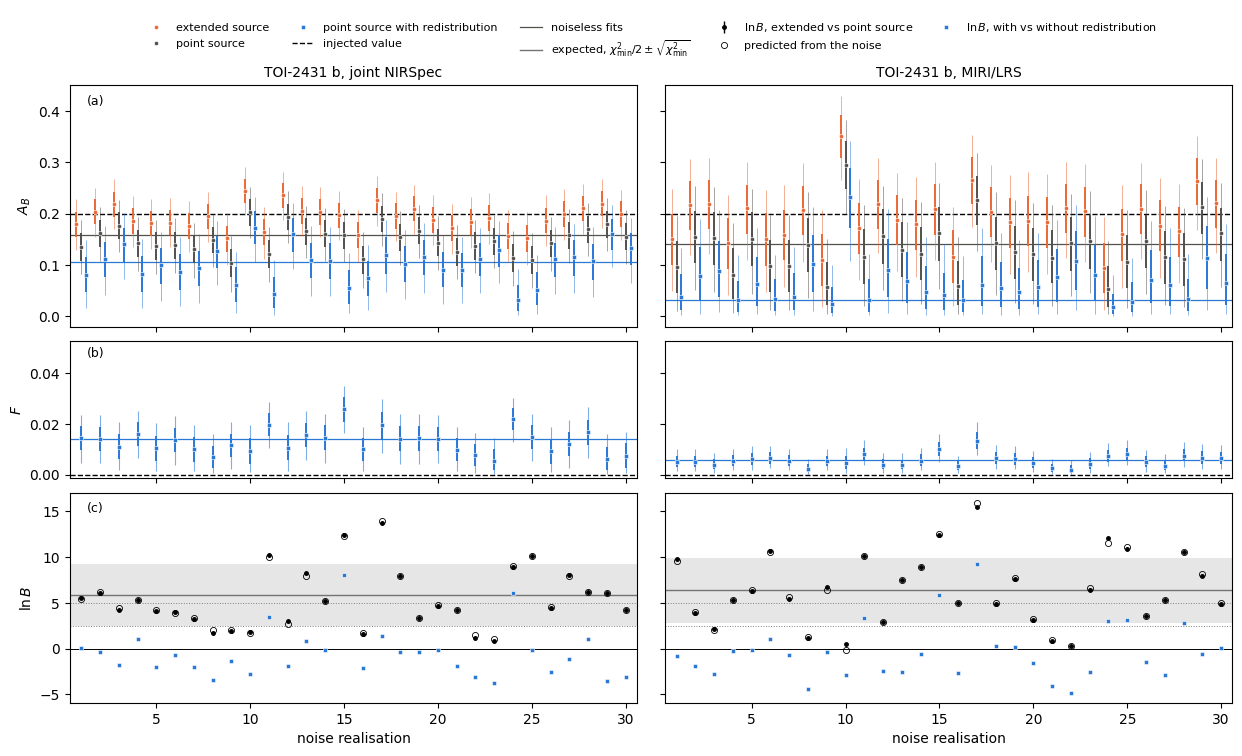

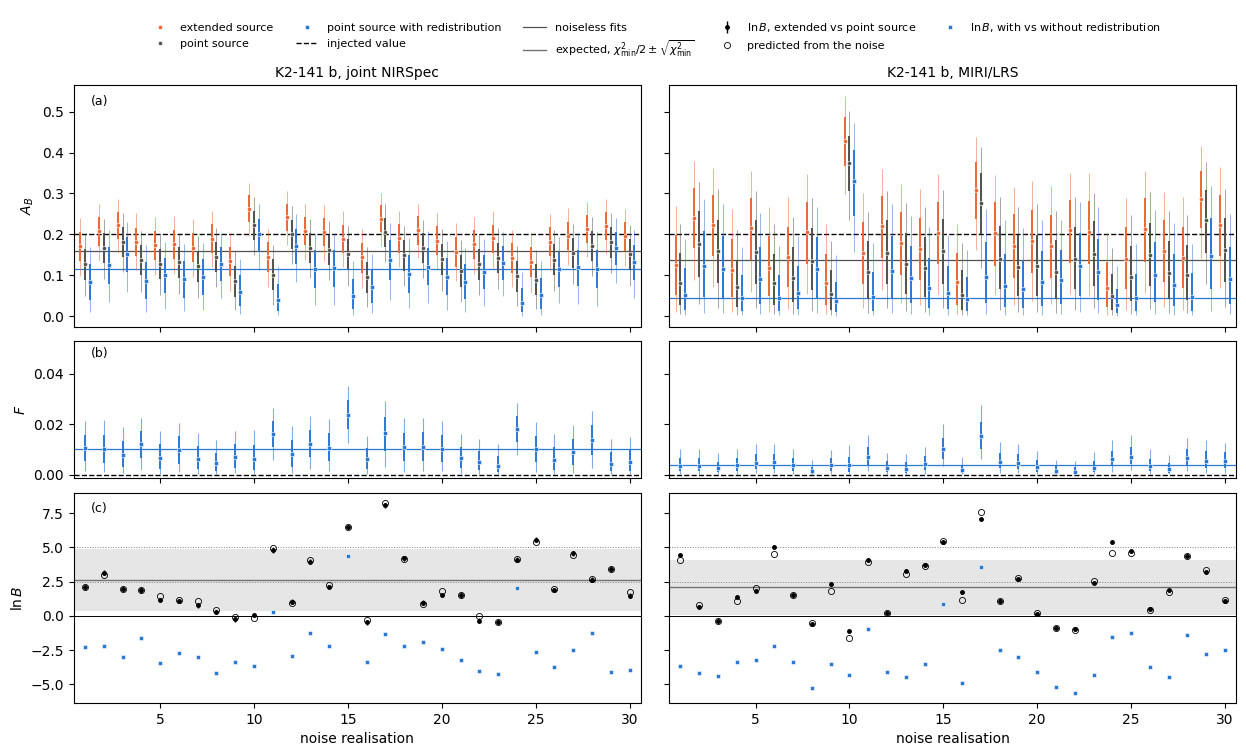

In [11]:
for planet in (T, K):
    cols = {f"{planet}, {lab}": (paper["planet"] == planet).to_numpy() & (paper["mode"] == lab).to_numpy() for lab in ("joint NIRSpec", "MIRI/LRS")}
    fig, _ = plot_ns_realizations(paper, cols, figsize=(15., 9.))
    plt.show()


**Figure `ns_distribution_<planet>`.** The same realisations as distributions (`plot_ns_distribution`), one row per mode: (a) the median $A_B$ of both point-source fits against that of the extended-source fit, with the line of equal medians shifted by each noiseless bias; (b) the fraction of realisations above a given $\ln B$ against the Gaussian prediction (grey: the other reference planet); (c) $z_F$ against $\ln B$, filled where $\ln B_F$ prefers redistribution.

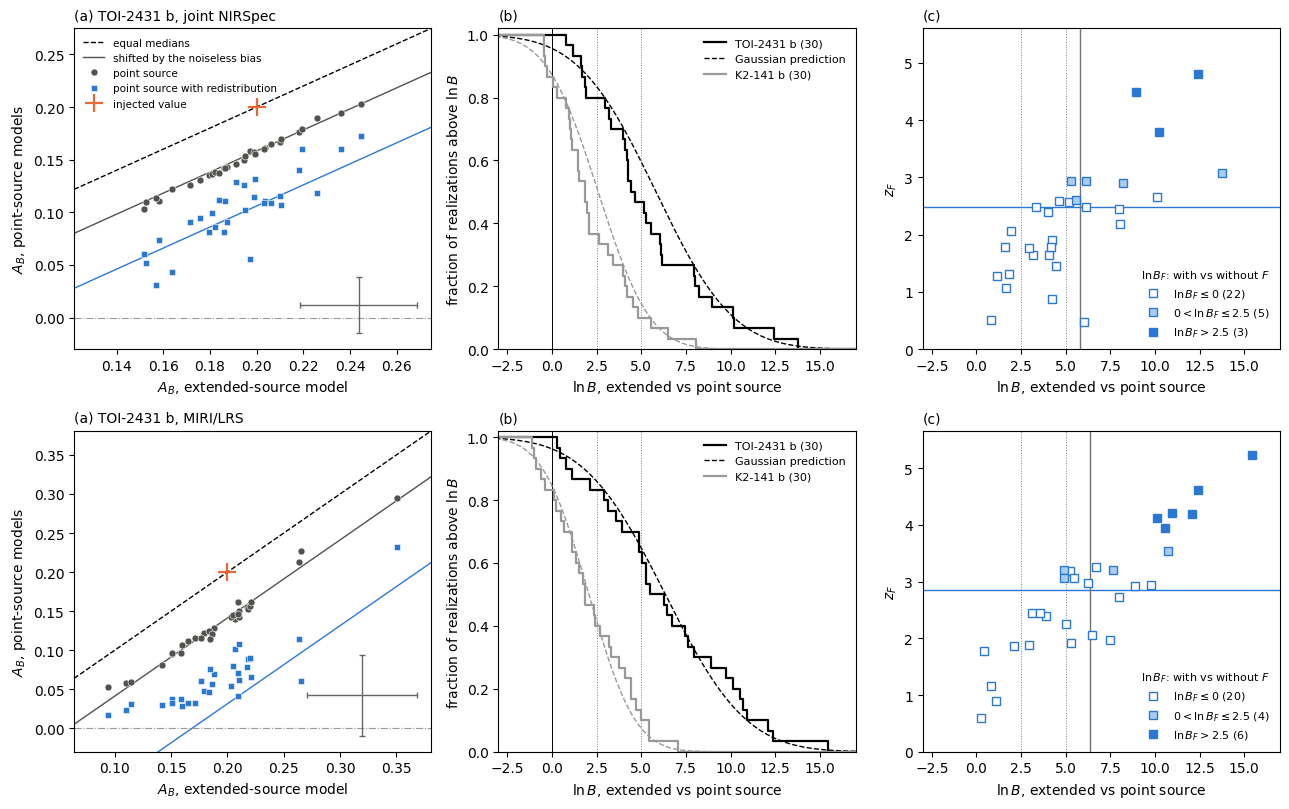

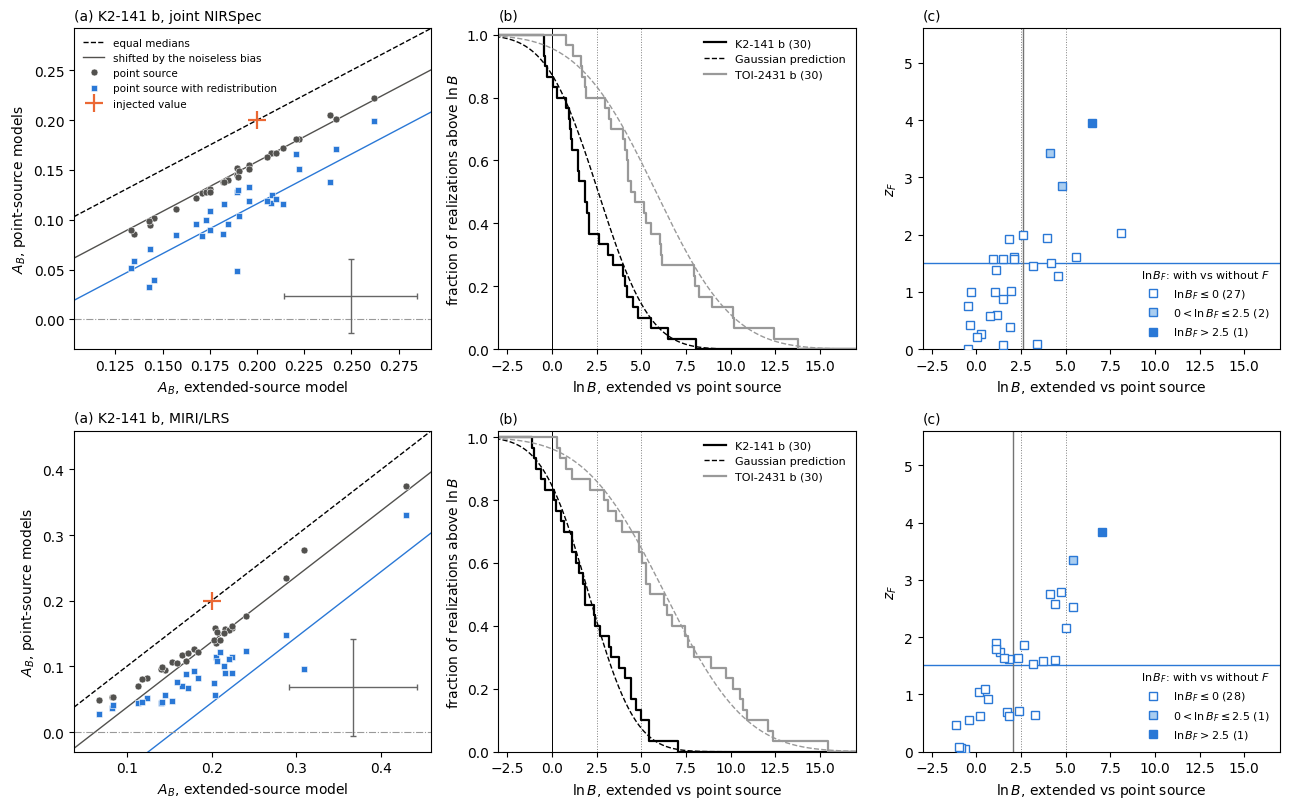

In [12]:
modes = ("joint NIRSpec", "MIRI/LRS")
of = lambda planet, lab: (paper["planet"] == planet).to_numpy() & (paper["mode"] == lab).to_numpy()
for planet, other in ((T, K), (K, T)):
    fig, _ = plot_ns_distribution(paper, {f"{planet}, {lab}": of(planet, lab) for lab in modes}, others=[{other: of(other, lab)} for lab in modes])
    plt.show()


**How representative are the seeds?** $\zeta$ and $|z|^2$ follow from the seed alone, so the cell compares the stored realisations of the reference planets with seeds 0–1999 without sampling, lists the predicted $\ln B$ of the next ten seeds, and prints the correlation of $\zeta$ between planets and modes. A stored block whose mean $\zeta$ lies outside about $\pm 1/\sqrt{n}$ of zero should be compared with its per-run predictions only.

In [13]:
MANY, NEXT = np.arange(2000), np.arange(max(PAPER_SEEDS[T]) + 1, max(PAPER_SEEDS[T]) + 11)   # the seeds of the distribution, and the next ten after the stored block
zeta_of, rows, nxt = {}, [], {}
for name in [f"{p}, {lab}" for p in (T, K) for lab in ("joint NIRSpec", "MIRI/LRS")]:
    t = paper[paper["series"] == name].sort_values("seed")
    ref = evidence_reference(load_fits(os.path.join(RESULTS_DIR, t["stem"].iloc[0] + "_*.pkl")), fisher=False, floor=False)   # r_perp and chi2_min of the configuration (seed-independent)
    r, c2 = ref["r_perp"], ref["chi2"]
    noise = lambda s: np.random.default_rng(int(s)).normal(0., 1., r.size)   # the standardised noise of a seed, as simulate_data draws it
    zeta_of[name] = z_all = np.array([r @ noise(s) / np.sqrt(c2) for s in MANY])
    stored, n = t["zeta"].to_numpy(), len(t)
    blocks = z_all[:len(MANY) // n * n].reshape(-1, n).mean(axis=1)   # means of blocks of n consecutive seeds
    rows.append({"series": name, "n": n, "ζ, stored seeds": f"{stored.mean():+.2f} ± {stored.std(ddof=1):.2f}", "ζ, seeds 0–1999": f"{z_all.mean():+.2f} ± {z_all.std(ddof=1):.2f}",
                 "blocks with a mean ζ this low": f"{np.mean(blocks <= stored.mean()):.3f}", "|z|²/bin, stored": f"{np.mean([noise(s) @ noise(s) for s in t['seed']]) / r.size:.2f}",
                 "|z|²/bin, next ten": f"{np.mean([noise(s) @ noise(s) for s in NEXT]) / r.size:.2f}"})
    nxt[name] = [0.5 * c2 + r @ noise(s) for s in NEXT]   # chi2_min / 2 + zeta sqrt(chi2_min)
display(pd.DataFrame(rows).set_index("series"))
print(f"predicted ln B (extended vs point source) of the next ten seeds, {NEXT[0]}–{NEXT[-1]} (linear prediction, no sampling):")
display(pd.DataFrame(nxt, index=pd.Index(NEXT, name="seed")).T.round(2).assign(mean=lambda f: f.mean(axis=1).round(2)))
print("correlation of ζ between the series over seeds 0–1999 (the same standardised noise in every series):")
display(pd.DataFrame(np.corrcoef(list(zeta_of.values())), index=list(zeta_of), columns=list(zeta_of)).round(2))


,n,"ζ, stored seeds","ζ, seeds 0–1999",blocks with a mean ζ this low,"|z|²/bin, stored","|z|²/bin, next ten"
series,,,,,,
"TOI-2431 b, joint NIRSpec",30,-0.11 ± 0.95,+0.01 ± 0.99,0.227,0.97,0.83
"TOI-2431 b, MIRI/LRS",30,+0.02 ± 1.10,-0.01 ± 1.00,0.621,0.91,0.87
"K2-141 b, joint NIRSpec",30,-0.10 ± 0.93,+0.01 ± 0.99,0.258,0.97,0.83
"K2-141 b, MIRI/LRS",30,+0.02 ± 1.08,-0.01 ± 1.00,0.621,0.91,0.87


predicted ln B (extended vs point source) of the next ten seeds, 70–79 (linear prediction, no sampling):


seed,70,71,72,73,74,75,76,77,78,79,mean
"TOI-2431 b, joint NIRSpec",3.93,7.21,5.75,-1.75,2.56,10.37,5.59,4.94,2.54,6.88,4.80
"TOI-2431 b, MIRI/LRS",7.47,6.69,8.86,4.38,5.76,10.39,7.94,3.65,2.42,3.58,6.11
"K2-141 b, joint NIRSpec",1.38,3.50,2.74,-2.39,0.46,6.30,2.56,1.77,0.79,3.26,2.04
"K2-141 b, MIRI/LRS",2.57,2.16,3.76,1.14,1.71,4.72,3.18,0.36,0.02,0.47,2.01


correlation of ζ between the series over seeds 0–1999 (the same standardised noise in every series):


,"TOI-2431 b, joint NIRSpec","TOI-2431 b, MIRI/LRS","K2-141 b, joint NIRSpec","K2-141 b, MIRI/LRS"
"TOI-2431 b, joint NIRSpec",1.00,0.62,0.99,0.62
"TOI-2431 b, MIRI/LRS",0.62,1.00,0.61,0.99
"K2-141 b, joint NIRSpec",0.99,0.61,1.00,0.62
"K2-141 b, MIRI/LRS",0.62,0.99,0.62,1.00
